# Online casino churn: 60-day survival forecast

This notebook runs the whole project end to end, from synthetic data to the scoring of
the current player base. The reusable logic lives in the `churn` package
(`generate_data`, `features`, `models`, `evaluation`, `pipeline`); the notebook calls it
step by step and shows every intermediate result.

Sections are numbered after the project requirements:

- **Data** and **Problem setup**: the generation script, churn labels, features, split
- **2-3** Cox and AFT models, tuned on the integrated Brier score of rolling-origin folds
- **4** test: predicted vs observed, **5** hazard: predicted vs observed
- **6** model quality and the best model, **7** Brier score and AUC over time
- **8** calibration, **9** bootstrap of the metrics
- **10** feature importance, **11** dependence plots for all feature pairs
- **12** remaining useful life vs Kaplan-Meier, **13** backtest
- **14** production model on every snapshot before the scoring date, **15** evaluation vs
  production
- **16** riskiest players, **17** their scoring
- **18** artifacts for the dashboard, **19** the dashboard

A full run takes about two minutes. It rewrites `data/` and `artifacts/` with the same
files that `python -m churn.generate_data` and `python -m churn.pipeline` produce.

In [1]:
import warnings

# Optuna imports tqdm.auto, which warns when ipywidgets is missing; no progress bar is used.
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import json
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import plotly.graph_objects as go
import shap
from IPython.display import display
from numpy.typing import ArrayLike
from plotly.subplots import make_subplots
from scipy.stats import spearmanr

from churn import config, features, generate_data
from churn import evaluation as ev
from churn.models import MODELS
from churn.pipeline import (
    MODEL_COLUMNS,
    Generations,
    backtest,
    describe,
    diagnostics,
    explain,
    forecast,
    rolling_fold,
    score_players,
    select_model,
    tune,
    xy,
)

N_TRIALS = 40  # Optuna trials per model
N_BOOTSTRAP = 200  # bootstrap resamples of the selection criterion and of the test metrics
SEED = config.SEED
DATA_DIR = config.DATA_DIR  # rewritten by the data step
ARTIFACTS_DIR = config.ARTIFACTS_DIR  # rewritten by step 18

TIMES = config.TIME_GRID  # days 1..85 on which survival curves are evaluated
HORIZON = config.HORIZON_DAYS
K_HORIZON = int(np.flatnonzero(TIMES == HORIZON)[0])  # column of the horizon in a curve matrix
FEATURES = list(config.FEATURES)

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.precision", 4, "display.max_columns", 40)

In [3]:
GREY = "#6b7280"
COLORS = {
    "cox": "#2563eb",
    "aft": "#f97316",
    "production": "#16a34a",
    "km_recency": "#a855f7",
    "all": GREY,
    "low": "#16a34a",
    "medium": "#f59e0b",
    "high": "#dc2626",
}
DASHES = {"raw": "dot", "calibrated": "solid"}


def line(
    x: ArrayLike,
    y: ArrayLike,
    name: str,
    color: str,
    dash: str = "solid",
    width: float = 2,
    **kwargs,
) -> go.Scatter:
    """Line trace."""
    style = {"color": color, "dash": dash, "width": width}
    return go.Scatter(x=x, y=y, name=name, mode="lines", line=style, **kwargs)


def show(
    fig: go.Figure,
    title: str,
    x_title: str | None = None,
    y_title: str | None = None,
    height: int = 420,
    **layout,
) -> None:
    """Apply the common layout and display the figure; ``None`` keeps an axis title."""
    titles = {"xaxis_title": x_title, "yaxis_title": y_title}
    fig.update_layout(
        title=title,
        template="plotly_white",
        height=height,
        margin={"l": 10, "r": 10, "t": 70, "b": 10},
        **{key: value for key, value in titles.items() if value is not None},
        **layout,
    )
    fig.show()

## Data: generation script

`churn/generate_data.py` simulates the players of an online casino day by day. Every
player moves through hidden states (engaged, fading, gone, with occasional win-backs).
The daily chance to start fading depends on the acquisition channel, the favourite game,
age, a latent engagement level, tenure, recent luck and recent bonuses. Only behaviour is
exported, so the models have to infer the hidden state from it.

The same script runs from the command line: `uv run python -m churn.generate_data`.

In [4]:
players, activity = generate_data.generate(seed=SEED)
DATA_DIR.mkdir(parents=True, exist_ok=True)
players.to_parquet(DATA_DIR / "players.parquet", index=False)
activity.to_parquet(DATA_DIR / "activity.parquet", index=False)

# Read the files back: the rest of the notebook works on what is stored on disk.
players, activity = features.load_raw(DATA_DIR)
first_day, last_day = activity["date"].min().date(), activity["date"].max().date()
print(f"{len(players):,} players, {len(activity):,} player-day rows, {first_day} .. {last_day}")
display(players.head(), activity.head())

20,000 players, 1,700,671 player-day rows, 2024-01-01 .. 2026-06-30


,player_id,registration_date,age,acquisition_channel,favorite_game
0,1,2024-03-22,23,organic,crash_games
1,2,2025-12-06,50,affiliate,slots
2,3,2025-08-19,41,affiliate,slots
3,4,2025-02-04,38,affiliate,table_games
4,5,2025-01-29,42,affiliate,table_games


,player_id,date,sessions,bets,turnover,ggr,deposits,withdrawals,bonus
0,2316,2024-01-01,1,73,33.61,16.18,20.93,0.0,0.0
1,2442,2024-01-01,1,70,90.95,28.54,109.15,0.0,0.0
2,3674,2024-01-01,1,42,19.73,0.79,16.66,0.0,0.0
3,5083,2024-01-01,1,26,50.00,-4.35,71.26,0.0,0.0
4,5760,2024-01-01,2,126,221.08,79.49,99.59,0.0,0.0


In [5]:
daily = activity.groupby("date").size()
fig = go.Figure(line(daily.index, daily, "active players", COLORS["cox"]))
show(fig, "Players active per day", "date", "players", height=300)

## Problem setup: churn, snapshots, labels, temporal split

- **Churn** is the first run of 30 consecutive days without activity. It is dated on the
  30th inactive day, the first moment it can be known without looking into the future.
  A player leaves the population after the first churn.
- **Snapshots.** On the first day of every month each player still at risk becomes one
  row. Features use activity strictly before the snapshot date; the target is the number
  of days from the snapshot to churn.
- **Censoring.** Labels are read on a cut-off date and followed for at most 90 days. A
  churn on the very last day of follow-up counts as censored, so every event lies
  strictly inside the follow-up window, which the IPCW-based metrics need.
- **Temporal split.** Train: snapshots 2024-07-01 .. 2025-12-01 with labels as known on
  2026-01-01. Validation: snapshot 2026-01-01. Test: snapshot 2026-04-01. Scoring:
  snapshot 2026-07-01, no labels yet. Validation and test hold one row per player.
- **Target.** `P(churn within 60 days) = 1 - S(60 | x)`; survival curves are evaluated on
  the daily grid 1..85, which stays inside the 90-day follow-up.
- **Time origin.** A player last active `r` days before the snapshot cannot churn during
  the first `30 - r` days. The column `churn_free_days` holds that delay. The models
  count time from its end and return `S = 1` before it; it is not a feature.
- **Decisions before the test.** Hyperparameters are tuned on the rolling-origin folds
  2025-07-01 and 2025-10-01; the model family and the use of calibration are chosen on
  the folds 2025-11-01 and 2025-12-01. Each fold is forecast from the snapshots before
  it, and all their labels are read on the test snapshot date at the latest.

In [6]:
snapshots = features.build_snapshots(players, activity, config.ALL_SNAPSHOTS)
data_cutoff = config.DATA_END + pd.Timedelta(days=1)  # first day without data
date = snapshots["snapshot_date"]
# Each split reads its labels on the date the next one starts, so nothing leaks backwards.
train = features.add_labels(snapshots[date.isin(config.TRAIN_SNAPSHOTS)], config.VAL_SNAPSHOT)
val = features.add_labels(snapshots[date == config.VAL_SNAPSHOT], config.TEST_SNAPSHOT)
test = features.add_labels(snapshots[date == config.TEST_SNAPSHOT], data_cutoff)
scoring = snapshots[date == config.SCORING_SNAPSHOT]
X_val, t_val, e_val = xy(val)
X_test, t_test, e_test = xy(test)

overview = pd.DataFrame.from_dict(
    {
        "train": describe(train),
        "val": describe(val, full_follow_up=True),
        "test": describe(test, full_follow_up=True),
        "scoring": {"rows": len(scoring)},
    },
    orient="index",
)
counts = ["rows", "players", "snapshots"]
overview[counts] = overview[counts].astype("Int64")
display(overview, test[["player_id", "snapshot_date", *MODEL_COLUMNS, "time", "event"]].head())

,rows,players,snapshots,event_rate,churn_rate_horizon
train,63229,13852,18,0.3481,NaN
val,4235,4235,1,0.3450,0.268
test,4201,4201,1,0.3325,0.258
scoring,4328,<NA>,<NA>,NaN,NaN


,player_id,snapshot_date,tenure_days,recency_days,active_days_7d,active_days_30d,activity_ratio_7d_30d,sessions_30d,turnover_30d,ggr_30d,deposits_30d,withdrawals_30d,bonus_30d,avg_stake_30d,age,acquisition_channel,favorite_game,churn_free_days,time,event
75880,2,2026-04-01,116,1,6,27,0.9524,58,4437.81,327.48,295.52,84.41,11.64,1.2568,50,affiliate,slots,29,90.0,False
75881,6,2026-04-01,38,1,3,15,0.8571,30,2217.96,101.30,450.31,115.06,28.04,1.8422,23,organic,crash_games,29,90.0,False
75882,8,2026-04-01,186,1,5,23,0.9317,45,601.01,-52.00,77.76,14.05,7.40,0.2191,30,affiliate,slots,29,90.0,False
75883,16,2026-04-01,105,1,2,14,0.6122,24,590.60,-31.03,96.53,32.73,7.46,0.3977,26,organic,slots,29,90.0,False
75884,19,2026-04-01,56,1,6,23,1.1180,52,7093.09,-143.11,884.00,102.41,282.32,5.5501,25,affiliate,live_casino,29,90.0,False


## 2-3. XGBoost Cox and AFT, tuned on rolling-origin folds

- **Cox** (`survival:cox`): the booster outputs a log hazard ratio `eta(x)`. With the
  Breslow baseline cumulative hazard `H0` estimated on the training data,
  `S(t | x) = exp(-H0(t) * exp(eta(x)))`.
- **AFT** (`survival:aft`): `log T = mu(x) + sigma * Z`, so
  `S(t | x) = P(Z > (log t - mu(x)) / sigma)`. The noise distribution and `sigma` are
  tuned.

Both models work on the player's own clock `u = t - churn_free_days`. They are trained
on the time left after the delay and return `S(t | x) = 1` while `u <= 0`; the formulas
above hold with `u` in place of `t`. Both expose `predict_survival(X, times)`, so
everything downstream is shared.

Optuna (TPE) minimises the integrated Brier score averaged over two rolling-origin folds
(`config.TUNE_SNAPSHOTS`). On each fold the model is fitted on the earlier snapshots with
the labels known on the fold date and predicts the players at risk on that date. The
validation and test snapshots take no part in it. The number of boosting rounds is tuned
directly instead of using early stopping, so every later refit can reuse it.

`Generations` then gives the model as of any date: fitted on the snapshots before that
date with the labels known on it, once, and reused by every later step.

In [7]:
tune_folds = [rolling_fold(snapshots, day, config.TEST_SNAPSHOT) for day in config.TUNE_SNAPSHOTS]
tuned, trials = {}, []
for name in MODELS:
    tuned[name], model_trials = tune(name, tune_folds, N_TRIALS, SEED)
    trials.append(model_trials)
tables = {"tuning_trials": pd.concat(trials, ignore_index=True)}  # all saved in step 18
tune_ibs = tables["tuning_trials"].groupby("model", sort=False)["ibs"].min().to_dict()

# Models as of any date, fitted once and reused by every later step. The generation of
# the validation date is the model fitted on `train`: the evaluation model.
generations = Generations(snapshots, tuned, SEED)
models = {name: generations.model(name, config.VAL_SNAPSHOT) for name in MODELS}
val_surv = {name: model.predict_survival(X_val, TIMES) for name, model in models.items()}
quality = [
    {
        "split": "val",
        "model": name,
        "variant": "raw",
        **ev.summary_metrics(t_val, e_val, surv, TIMES, HORIZON),
    }
    for name, surv in val_surv.items()
]
val_ibs = {row["model"]: row["ibs"] for row in quality}

best_params = pd.DataFrame(tuned).map(
    lambda v: "" if pd.isna(v) else f"{v:.4g}" if isinstance(v, float) else str(v)
)
print(f"Mean IBS over the tuning folds: {tune_ibs}")
display(best_params.rename_axis("hyperparameter"), pd.DataFrame(quality))

Mean IBS over the tuning folds: {'cox': 0.07158332738992443, 'aft': 0.07115537182649938}


,cox,aft
hyperparameter,,
num_boost_round,275,125
learning_rate,0.07323,0.1317
max_depth,4,5
min_child_weight,40.62,12.92
subsample,0.8909,0.7971
colsample_bytree,0.6386,0.7893
lambda,0.6606,9.598
max_delta_step,0.1533,
aft_loss_distribution,,logistic


,split,model,variant,c_index,ibs,brier_horizon,auc_horizon
0,val,cox,raw,0.8376,0.0676,0.1058,0.8747
1,val,aft,raw,0.8311,0.0677,0.1076,0.8706


In [8]:
fig = go.Figure()
for name, part in tables["tuning_trials"].groupby("model", sort=False):
    marker = {"color": COLORS[name], "opacity": 0.4}
    points = go.Scatter(
        x=part["trial"], y=part["ibs"], mode="markers", name=f"{name}: trial", marker=marker
    )
    fig.add_trace(points)
    fig.add_trace(line(part["trial"], part["best_ibs"], f"{name}: best so far", COLORS[name]))
title = "Optuna search: mean IBS over the tuning folds"
show(fig, title, "trial", "IBS (log scale)", yaxis_type="log")

Requirement 8 asks for calibrated models. The calibrators are fitted here, on the
validation snapshot, because steps 4-7 report raw and calibrated predictions side by
side; step 8 looks at the calibration itself.

At every day `t` of the grid an isotonic regression maps the predicted `1 - S(t | x)`
onto the observed frequency of churn by day `t`; the calibrated curves are then made
non-increasing in `t`. No IPCW is needed: on validation nobody is censored before the
end of the grid, which `fit` checks.

A day on which a player cannot churn yet has a raw probability of exactly zero, and the
isotonic map keeps it at zero. Whether the scores use the calibrated curves is decided in
step 6, on folds of their own.

In [9]:
calibrators, test_surv = {}, {}
for name, model in models.items():
    # The calibrator of the validation generation: fitted on `val`, labels read on the test date.
    calibrators[name] = generations.calibrator(name, config.VAL_SNAPSHOT, config.TEST_SNAPSHOT)
    raw = model.predict_survival(X_test, TIMES)
    test_surv[(name, "raw")] = raw
    test_surv[(name, "calibrated")] = calibrators[name].transform(raw, TIMES)
variant_titles = [f"{name} {variant}" for name, variant in test_surv]

## 4. Test: predicted vs observed

Three views of the same question, on the untouched test snapshot:

- the mean predicted survival curve against the Kaplan-Meier estimate of what happened;
- the mean predicted churn probability against the observed churn rate at 7, 14, 30 and
  60 days;
- predicted against observed 60-day churn by decile of predicted risk.

In [10]:
tables |= diagnostics(t_test, e_test, test_surv)

curves = tables["survival_curves"]
observed = curves.drop_duplicates("day")
fig = go.Figure(
    line(observed["day"], observed["observed"], "observed (Kaplan-Meier)", GREY, width=5)
)
for (name, variant), part in curves.groupby(["model", "variant"], sort=False):
    label = f"{name} {variant}"
    fig.add_trace(line(part["day"], part["predicted"], label, COLORS[name], DASHES[variant]))
show(
    fig,
    "Test: mean predicted survival vs Kaplan-Meier",
    "days since snapshot",
    "share of players not churned",
    yaxis_tickformat=".0%",
)

In [11]:
at_horizons = np.isin(TIMES, config.SCORE_HORIZONS)
rates = {
    f"{name} {variant}": 1 - surv[:, at_horizons].mean(axis=0)
    for (name, variant), surv in test_surv.items()
}
rates["observed"] = [(e_test & (t_test <= h)).mean() for h in config.SCORE_HORIZONS]
display(pd.DataFrame(rates, index=[f"churn by day {h}" for h in config.SCORE_HORIZONS]).T)

,churn by day 7,churn by day 14,churn by day 30,churn by day 60
cox raw,0.0252,0.0552,0.1487,0.2575
cox calibrated,0.0361,0.0711,0.1595,0.2622
aft raw,0.0263,0.0585,0.1435,0.2782
aft calibrated,0.0359,0.0711,0.1559,0.2637
observed,0.0364,0.0714,0.1485,0.2580


In [12]:
deciles = tables["calibration"].query("horizon == @HORIZON")
fig = make_subplots(rows=1, cols=4, subplot_titles=variant_titles, shared_yaxes=True)
for col, (name, variant) in enumerate(test_surv, start=1):
    part = deciles[(deciles["model"] == name) & (deciles["variant"] == variant)]
    fig.add_trace(go.Bar(x=part["bin"], y=part["predicted"], marker_color=COLORS[name]), 1, col)
    fig.add_trace(go.Bar(x=part["bin"], y=part["observed"], marker_color=GREY), 1, col)
fig.update_xaxes(title_text="risk decile")
fig.update_yaxes(tickformat=".0%")
show(
    fig,
    f"Test: churn within {HORIZON} days by risk decile, predicted (colour) vs observed (grey)",
    height=360,
    showlegend=False,
)

## 5. Hazard: predicted vs observed

The observed hazard on day `t` is the number of players who churned on that day divided
by the number still at risk. The predicted hazard is the one of the group's mean
predicted curve, `1 - S(t) / S(t - 1)`, which is what the observed ratio estimates in a
heterogeneous group. Groups are terciles of the predicted 60-day churn probability.

A player last active `r` days before the snapshot cannot churn before day `31 - r`, so a
group of recently active players has no hazard at all during the first weeks. The models
start their clock on that day, so their predicted hazard is zero there as well.

In [13]:
hazard = tables["hazard"]
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=variant_titles,
    shared_xaxes=True,
    shared_yaxes=True,
    vertical_spacing=0.1,
)
for position, (name, variant) in enumerate(test_surv):
    row, col = position // 2 + 1, position % 2 + 1
    part = hazard[(hazard["model"] == name) & (hazard["variant"] == variant)]
    for group, days in part.groupby("group", sort=False):
        smooth = days[["predicted", "observed"]].rolling(7, center=True, min_periods=1).mean()
        color, legend = COLORS[group], {"legendgroup": group, "showlegend": position == 0}
        fig.add_trace(line(days["day"], smooth["predicted"], group, color, **legend), row, col)
        legend["showlegend"] = False
        fig.add_trace(
            line(days["day"], smooth["observed"], group, color, "dot", **legend), row, col
        )
fig.update_xaxes(title_text="days since snapshot", row=2)
fig.update_yaxes(tickformat=".1%")
show(
    fig,
    "Test: daily churn hazard by risk group, predicted (solid) vs observed (dotted), "
    "7-day moving average",
    height=620,
)

## 6. Model quality and the best model

The best model is chosen without the validation and test snapshots. The two selection
folds (`config.SELECTION_SNAPSHOTS`) are forecast the way the current players are scored:
the models are refitted on all earlier snapshots, and the calibrated variant uses the
calibrator of the generation three months older, the latest one whose snapshot has been
followed for the whole grid. The criterion is the integrated Brier score averaged over
the folds.

- A family is represented by its calibrated curves only if the 95% interval of
  `calibrated - raw` lies below zero, otherwise by the raw ones.
- The family with the lower criterion wins. The interval of its difference to the
  runner-up tells whether the folds can tell the two apart.

The intervals come from a bootstrap over players, not rows: a player is at risk on both
folds.

In [14]:
selection_folds = [
    forecast(generations, day, config.TEST_SNAPSHOT) for day in config.SELECTION_SNAPSHOTS
]
selection, tables["selection"] = select_model(selection_folds, N_BOOTSTRAP, SEED)
best, best_variant = selection["best_model"], selection["best_variant"]

effects = [*selection["calibration_effect"].values(), selection["best_vs_runner_up"]]
display(tables["selection"], pd.DataFrame(effects).set_index("pair"))
print(f"Selected: {best}, {best_variant}")

,model,variant,point,mean,ci_low,ci_high,selected
0,cox,raw,0.0707,0.0709,0.0679,0.0735,False
1,cox,calibrated,0.0692,0.0694,0.0666,0.0722,True
2,aft,raw,0.0705,0.0707,0.0677,0.0733,False
3,aft,calibrated,0.0696,0.0698,0.0667,0.0725,False


,point,ci_low,ci_high,significant
pair,,,,
cox_calibrated - cox_raw,-0.0014,-0.0018,-1.0513e-03,True
aft_calibrated - aft_raw,-0.0009,-0.0013,-5.1569e-04,True
cox_calibrated - aft_calibrated,-0.0004,-0.0007,3.7945e-05,False


Selected: cox, calibrated


Quality of the evaluation models on validation and test:

- `c_index`: Harrell's concordance of the 60-day churn probability with the durations.
- `ibs`: integrated Brier score over the grid (lower is better), the tuning target.
- `brier_horizon`, `auc_horizon`: IPCW Brier score and cumulative/dynamic AUC at 60 days.

Two rows use no model. `kaplan_meier` is the Kaplan-Meier curve of the training data
assigned to every test player. `km_recency` is one training curve per value of
`recency_days`: what the churn definition alone gives, and the bar a model has to clear.
The test numbers are a report; no decision depends on them.

In [15]:
t_train, e_train = train["time"].to_numpy(), train["event"].to_numpy()
km_train = ev.km_on_grid(t_train, e_train, TIMES)
recency_train, recency_test = (frame["recency_days"].to_numpy() for frame in (train, test))
km_recency = ev.km_by_group(t_train, e_train, recency_train, recency_test, TIMES)
reference = {
    ("kaplan_meier", "raw"): np.tile(km_train, (len(test), 1)),
    ("km_recency", "raw"): km_recency,
}
for (name, variant), surv in (test_surv | reference).items():
    metrics = ev.summary_metrics(t_test, e_test, surv, TIMES, HORIZON)
    quality.append({"split": "test", "model": name, "variant": variant, **metrics})
tables["model_quality"] = pd.DataFrame(quality)
display(tables["model_quality"])

,split,model,variant,c_index,ibs,brier_horizon,auc_horizon
0,val,cox,raw,0.8376,0.0676,0.1058,0.8747
1,val,aft,raw,0.8311,0.0677,0.1076,0.8706
2,test,cox,raw,0.8239,0.0711,0.1091,0.8619
3,test,cox,calibrated,0.8212,0.0705,0.1098,0.8604
4,test,aft,raw,0.8202,0.0712,0.1103,0.8617
5,test,aft,calibrated,0.8192,0.0705,0.1097,0.8609
6,test,kaplan_meier,raw,0.5000,0.1446,0.1922,0.5000
7,test,km_recency,raw,0.7674,0.0763,0.1201,0.8074


Players inactive for a long time churn almost surely and dominate the pooled metrics. The
same metrics within groups of `recency_days` show how the models do on recently active
players, the ones that can still be retained. Within a group the IBS covers only the days
that the group's follow-up supports, so compare models within a group, not groups with
each other.

In [16]:
parts = [
    ev.stratified_metrics(t_test, e_test, surv, TIMES, HORIZON, recency_test, [bounds]).assign(
        model=name, variant=variant
    )
    for bounds in config.RECENCY_STRATA
    for (name, variant), surv in (test_surv | {("km_recency", "raw"): km_recency}).items()
]
strata = pd.concat(parts, ignore_index=True)
leading = ["stratum", "model", "variant"]
tables["quality_by_recency"] = strata[leading + [c for c in strata if c not in leading]]
display(tables["quality_by_recency"])

,stratum,model,variant,n,churn_rate_horizon,c_index,ibs,brier_horizon,auc_horizon
0,1-3,cox,raw,3148,0.1271,0.6949,0.0873,0.1000,0.7258
1,1-3,cox,calibrated,3148,0.1271,0.6913,0.0875,0.1002,0.7219
2,1-3,aft,raw,3148,0.1271,0.6902,0.0875,0.1001,0.7235
3,1-3,aft,calibrated,3148,0.1271,0.6875,0.0874,0.0999,0.7225
4,1-3,km_recency,raw,3148,0.1271,0.5568,0.0958,0.1100,0.5777
5,4-7,cox,raw,457,0.3501,0.6613,0.1852,0.1997,0.7043
6,4-7,cox,calibrated,457,0.3501,0.6591,0.1867,0.2027,0.7000
7,4-7,aft,raw,457,0.3501,0.6584,0.1875,0.2046,0.7015
8,4-7,aft,calibrated,457,0.3501,0.6557,0.1879,0.2031,0.6981
9,4-7,km_recency,raw,457,0.3501,0.5692,0.2040,0.2227,0.5838


## 7. Brier score and AUC over time

Both metrics are computed at every day of the grid with inverse-probability-of-censoring
weights. The dashed line marks the 60-day business horizon.

In [17]:
over_time = tables["metrics_over_time"]
titles = ["Brier score (lower is better)", "cumulative/dynamic AUC (higher is better)"]
fig = make_subplots(rows=1, cols=2, subplot_titles=titles)
for (name, variant), part in over_time.groupby(["model", "variant"], sort=False):
    label = f"{name} {variant}"
    for col, metric in enumerate(("brier", "auc"), start=1):
        legend = {"legendgroup": label, "showlegend": col == 1}
        trace = line(part["day"], part[metric], label, COLORS[name], DASHES[variant], **legend)
        fig.add_trace(trace, 1, col)
fig.add_vline(x=HORIZON, line_dash="dash", line_color=GREY)
fig.update_xaxes(title_text="days since snapshot")
show(fig, "Test: time-dependent Brier score and AUC")

selected = over_time[over_time["day"].isin(config.SCORE_HORIZONS)]
display(selected.pivot(index=["model", "variant"], columns="day", values=["brier", "auc"]))

brier                             auc                  \
day                   7       14      30      60      7       14      30   
model variant                                                              
aft   calibrated  0.0009  0.0033  0.0455  0.1097  0.9998  0.9990  0.9608   
      raw         0.0040  0.0063  0.0443  0.1103  0.9998  0.9990  0.9618   
cox   calibrated  0.0007  0.0036  0.0464  0.1098  0.9997  0.9989  0.9591   
      raw         0.0041  0.0071  0.0454  0.1091  0.9998  0.9989  0.9589   

                          
day                   60  
model variant             
aft   calibrated  0.8609  
      raw         0.8617  
cox   calibrated  0.8604  
      raw         0.8619

## 8. Calibration

The calibrators were fitted on validation right after tuning. Here is what they do:

- the isotonic map at the 60-day horizon (raw probability in, calibrated probability out);
- reliability on test before and after: predicted against observed churn rate by risk
  decile, where a perfectly calibrated model lies on the diagonal;
- the mean absolute gap between predicted and observed churn rate across the deciles, at
  every scoring horizon.

Whether calibration changes the metrics by more than noise is tested in step 9.

In [18]:
fig = go.Figure(line([0, 1], [0, 1], "identity", GREY, "dash"))
for name, calibrator in calibrators.items():
    raw_probability, calibrated_probability = calibrator.knots_[K_HORIZON]
    fig.add_trace(line(raw_probability, calibrated_probability, name, COLORS[name]))
show(
    fig,
    f"Isotonic calibration maps at {HORIZON} days (fitted on validation)",
    "raw P(churn)",
    "calibrated P(churn)",
    height=380,
)

In [19]:
fig = make_subplots(rows=1, cols=len(MODELS), subplot_titles=list(MODELS), shared_yaxes=True)
for col, name in enumerate(MODELS, start=1):
    fig.add_trace(line([0, 1], [0, 1], "perfect", GREY, "dash", showlegend=col == 1), 1, col)
    for variant, dash in DASHES.items():
        part = deciles[(deciles["model"] == name) & (deciles["variant"] == variant)]
        curve = go.Scatter(
            x=part["predicted"],
            y=part["observed"],
            mode="lines+markers",
            name=f"{name} {variant}",
            line={"color": COLORS[name], "dash": dash},
        )
        fig.add_trace(curve, 1, col)
fig.update_xaxes(title_text="predicted churn rate", tickformat=".0%")
fig.update_yaxes(tickformat=".0%")
show(fig, f"Test: reliability at {HORIZON} days by risk decile", y_title="observed churn rate")

gap = tables["calibration"].assign(gap=lambda d: (d["predicted"] - d["observed"]).abs())
gap = gap.pivot_table(index=["model", "variant"], columns="horizon", values="gap", aggfunc="mean")
display(gap.rename_axis(columns="mean |predicted - observed| at day"))

mean |predicted - observed| at day      7       14      30      60
model variant                                                     
aft   calibrated                    0.0005  0.0003  0.0161  0.0163
      raw                           0.0101  0.0129  0.0129  0.0260
cox   calibrated                    0.0003  0.0003  0.0159  0.0185
      raw                           0.0112  0.0162  0.0221  0.0123

## 9. Bootstrap of the metrics

Test players are resampled with replacement (one row per player, so rows are
independent). The same resample is used for every model, which makes the differences
paired: an interval that excludes zero means the difference is larger than what
resampling noise explains.

Every model is also compared with `km_recency`, the reference that knows the churn
definition and nothing else.

In [20]:
named = {f"{name}_{variant}": surv for (name, variant), surv in test_surv.items()}
named["km_recency_raw"] = km_recency
draws = ev.bootstrap_metrics(t_test, e_test, named, TIMES, HORIZON, N_BOOTSTRAP, SEED)

point = tables["model_quality"].query("split == 'test' and model != 'kaplan_meier'")
point = point.assign(model=point["model"] + "_" + point["variant"]).melt(
    id_vars="model", value_vars=list(ev.METRICS), var_name="metric", value_name="point"
)
tables["bootstrap_summary"] = ev.bootstrap_summary(draws).merge(point, on=["model", "metric"])
pairs = [("cox_raw", "aft_raw"), ("cox_calibrated", "aft_calibrated")]
pairs += [(f"{name}_calibrated", f"{name}_raw") for name in MODELS]
pairs += [(key, "km_recency_raw") for key in named if key != "km_recency_raw"]
tables["bootstrap_differences"] = pd.concat(
    [ev.bootstrap_difference(draws, a, b) for a, b in pairs], ignore_index=True
)
tables["bootstrap_draws"] = draws

In [21]:
summary = tables["bootstrap_summary"]
fig = make_subplots(
    rows=1, cols=len(ev.METRICS), subplot_titles=list(ev.METRICS), shared_yaxes=True
)
for col, metric in enumerate(ev.METRICS, start=1):
    part = summary[summary["metric"] == metric]
    interval = {
        "type": "data",
        "symmetric": False,
        "array": part["ci_high"] - part["point"],
        "arrayminus": part["point"] - part["ci_low"],
        "color": GREY,
    }
    marker = {"size": 10, "color": [COLORS[key.rsplit("_", 1)[0]] for key in part["model"]]}
    estimate = go.Scatter(
        x=part["point"], y=part["model"], mode="markers", marker=marker, error_x=interval
    )
    fig.add_trace(estimate, 1, col)
show(
    fig,
    f"Test metrics with 95% bootstrap intervals ({N_BOOTSTRAP} resamples of players)",
    height=320,
    showlegend=False,
)

differences = tables["bootstrap_differences"]
excludes_zero = (differences["ci_low"] > 0) | (differences["ci_high"] < 0)
readable = differences.assign(excludes_zero=excludes_zero)
bounds = ["mean", "ci_low", "ci_high"]
readable[bounds] = readable[bounds].map("{:+.5f}".format)  # the differences are tiny
display(summary, readable)

,model,metric,mean,ci_low,ci_high,point
0,cox_raw,c_index,0.8237,0.8112,0.8348,0.8239
1,cox_raw,ibs,0.0711,0.0669,0.0750,0.0711
2,cox_raw,brier_horizon,0.1090,0.1017,0.1161,0.1091
3,cox_raw,auc_horizon,0.8616,0.8462,0.8738,0.8619
4,cox_calibrated,c_index,0.8211,0.8081,0.8315,0.8212
5,cox_calibrated,ibs,0.0705,0.0663,0.0744,0.0705
6,cox_calibrated,brier_horizon,0.1098,0.1026,0.1168,0.1098
7,cox_calibrated,auc_horizon,0.8601,0.8447,0.8726,0.8604
8,aft_raw,c_index,0.8201,0.8068,0.8310,0.8202
9,aft_raw,ibs,0.0711,0.0668,0.0749,0.0712


,model,metric,mean,ci_low,ci_high,excludes_zero
0,cox_raw - aft_raw,auc_horizon,+0.00016,-0.00307,+0.00331,False
1,cox_raw - aft_raw,brier_horizon,-0.00124,-0.00264,+0.00035,False
2,cox_raw - aft_raw,c_index,+0.00367,+0.00017,+0.00642,True
3,cox_raw - aft_raw,ibs,-0.00003,-0.00084,+0.00081,False
4,cox_calibrated - aft_calibrated,auc_horizon,-0.00055,-0.00442,+0.00307,False
5,cox_calibrated - aft_calibrated,brier_horizon,+0.00020,-0.00073,+0.00139,False
6,cox_calibrated - aft_calibrated,c_index,+0.00196,-0.00114,+0.00516,False
7,cox_calibrated - aft_calibrated,ibs,+0.00007,-0.00054,+0.00085,False
8,cox_calibrated - cox_raw,auc_horizon,-0.00149,-0.00260,-0.00040,True
9,cox_calibrated - cox_raw,brier_horizon,+0.00078,-0.00006,+0.00155,False


## 10. Feature importance

Two measures for every model:

- `gain_share`: the share of the total split gain that goes to a feature;
- `mean_abs_shap`: the mean absolute TreeSHAP contribution on a sample of test players.
  Contributions are oriented so that a positive value pushes towards churn.

Cox explains a log hazard and AFT a log time, so the SHAP magnitudes are shown as shares
within a model. The production model joins the comparison in step 14.

Both measures describe the booster, that is the time left once churn is possible. The
churn-free delay that `recency_days` fixes by definition is not learned, so it carries
no importance.

In [22]:
explained = {name: explain(model, name, X_test, SEED) for name, model in models.items()}


def importance_chart(importance: pd.DataFrame, title: str) -> None:
    """Grouped bars of the two importance measures, one bar group per model."""
    kinds = {"mean_abs_shap": "share of mean |SHAP|", "gain_share": "share of split gain"}
    shares = importance.copy()
    shares["mean_abs_shap"] /= shares.groupby("model")["mean_abs_shap"].transform("sum")
    order = shares.groupby("feature")["mean_abs_shap"].mean().sort_values().index
    fig = make_subplots(rows=1, cols=2, subplot_titles=list(kinds.values()), shared_yaxes=True)
    for name, part in shares.groupby("model", sort=False):
        part = part.set_index("feature").loc[order]
        for col, kind in enumerate(kinds, start=1):
            bars = go.Bar(
                y=order,
                x=part[kind],
                name=name,
                orientation="h",
                marker_color=COLORS[name],
                legendgroup=name,
                showlegend=col == 1,
            )
            fig.add_trace(bars, 1, col)
    fig.update_xaxes(tickformat=".0%")
    show(fig, title, height=520, barmode="group")


importance = pd.concat([table for table, _ in explained.values()], ignore_index=True)
importance_chart(importance, "Feature importance of the evaluation models (test sample)")
wide = importance.pivot(index="feature", columns="model", values=["gain_share", "mean_abs_shap"])
display(wide.sort_values(("mean_abs_shap", best), ascending=False))

gain_share         mean_abs_shap        
model                        aft     cox           aft     cox
feature                                                       
recency_days              0.1543  0.4075        0.9457  0.3620
active_days_7d            0.7325  0.3305        1.4023  0.2938
active_days_30d           0.0072  0.0958        0.1606  0.2389
acquisition_channel       0.0129  0.0238        0.3271  0.2115
activity_ratio_7d_30d     0.0178  0.0713        0.1461  0.1707
tenure_days               0.0079  0.0230        0.1651  0.1122
sessions_30d              0.0503  0.0181        0.0950  0.0841
age                       0.0027  0.0058        0.1061  0.0681
ggr_30d                   0.0027  0.0051        0.0912  0.0616
bonus_30d                 0.0023  0.0035        0.1056  0.0554
favorite_game             0.0019  0.0056        0.0815  0.0530
withdrawals_30d           0.0019  0.0015        0.0451  0.0217
turnover_30d              0.0019  0.0041        0.0431  0.0209
deposits_30d              0.0016  0.0019        0.0508  0.0180
avg_stake_30d             0.0021  0.0025        0.0612  0.0172

## 11. Dependence plots for all feature pairs

A SHAP dependence plot shows the value of a feature on the x axis and its contribution to
the risk score on the y axis; colouring the points by a second feature reveals
interactions. The plots are drawn by `shap.dependence_plot` from the TreeSHAP values of
step 10. Below there is one figure per feature with one panel per colouring feature,
which covers every ordered pair of features.

Colour runs from blue (low value of the feature named on the colour bar) to red (high
value), clipped to the 5th-95th percentile. Categorical features are drawn at integer
positions and labelled with their categories. A little horizontal jitter separates the
points of discrete features. Every panel shows the whole explained sample.

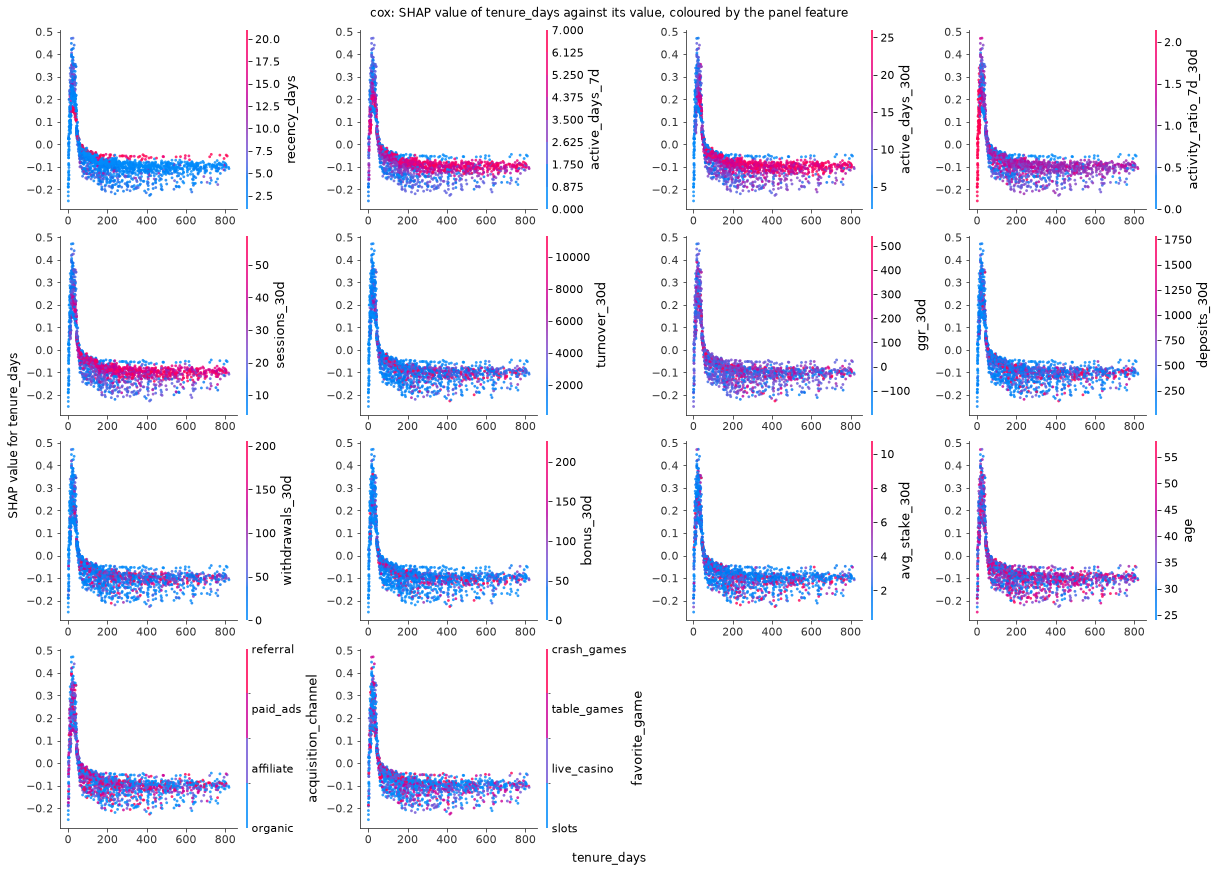

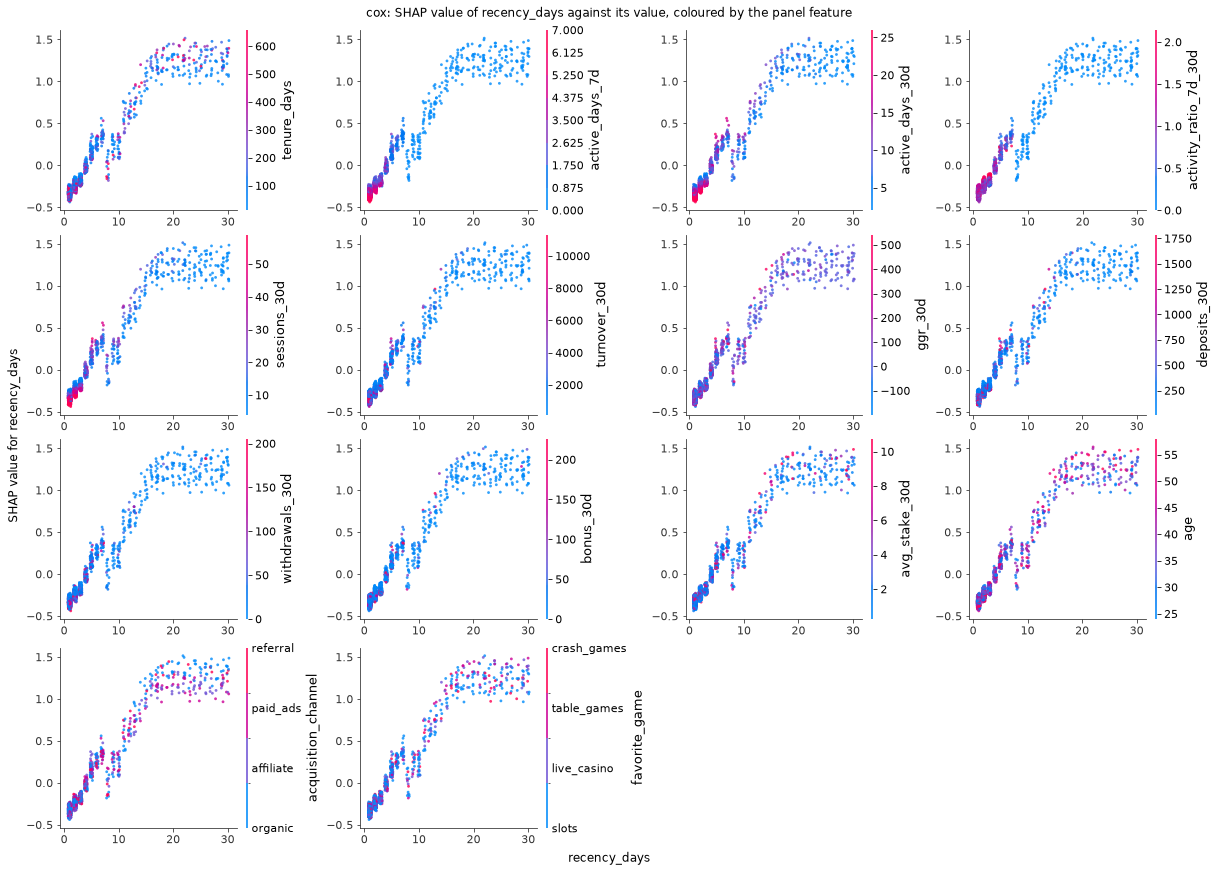

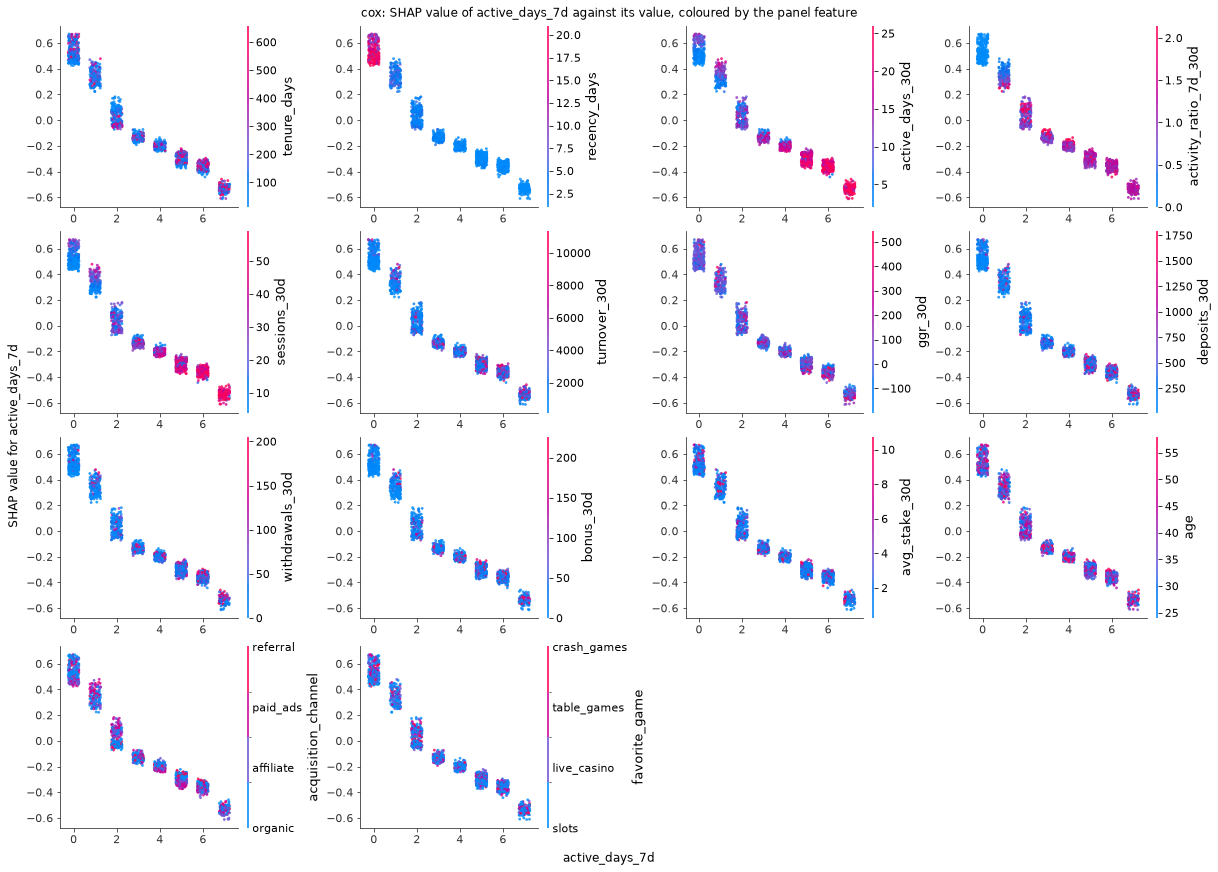

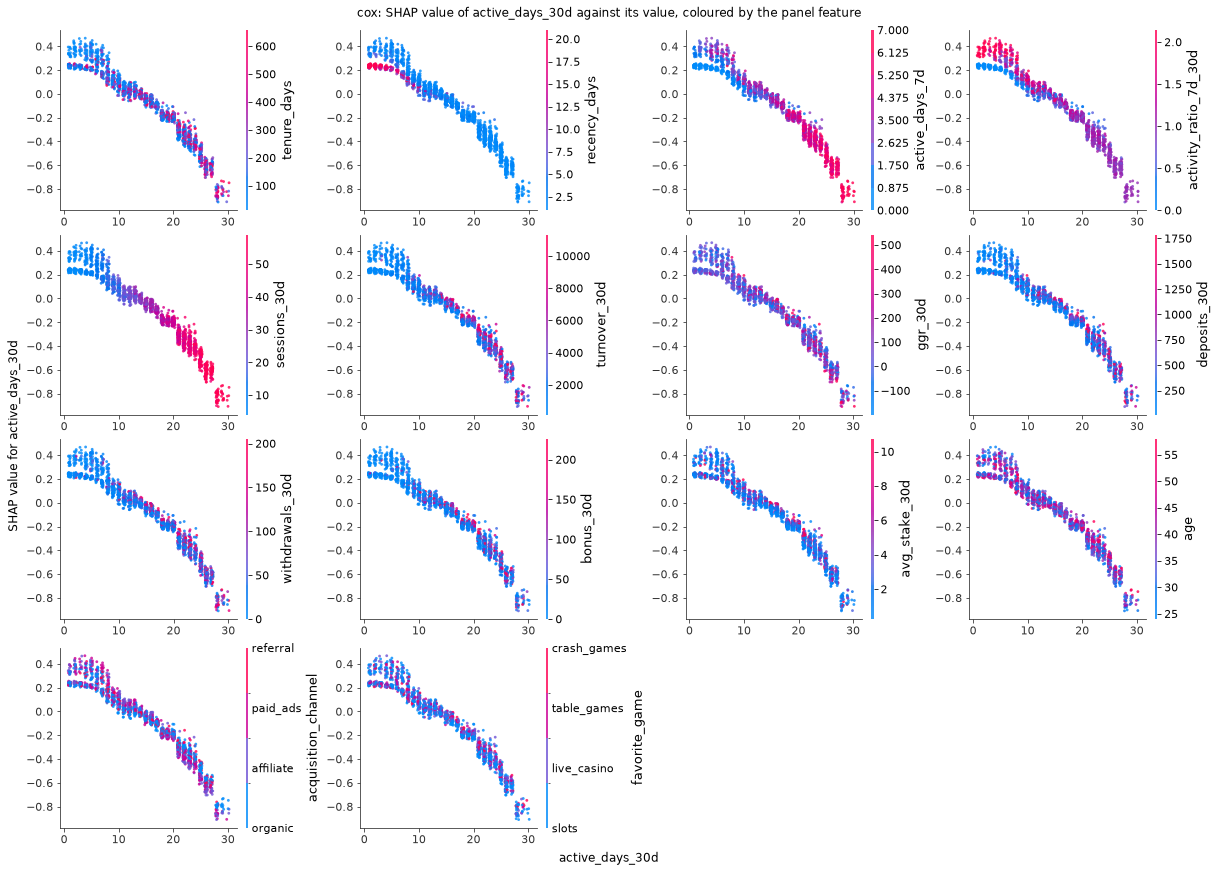

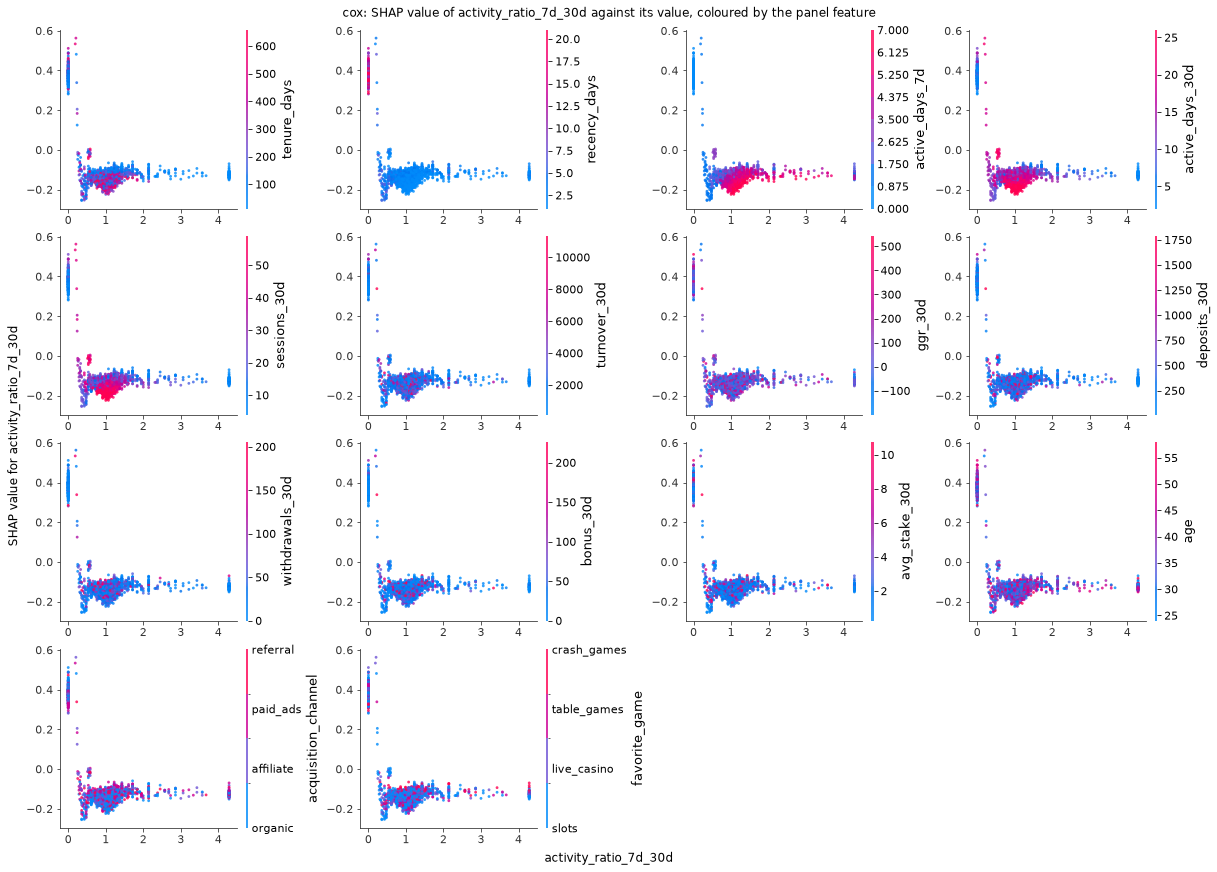

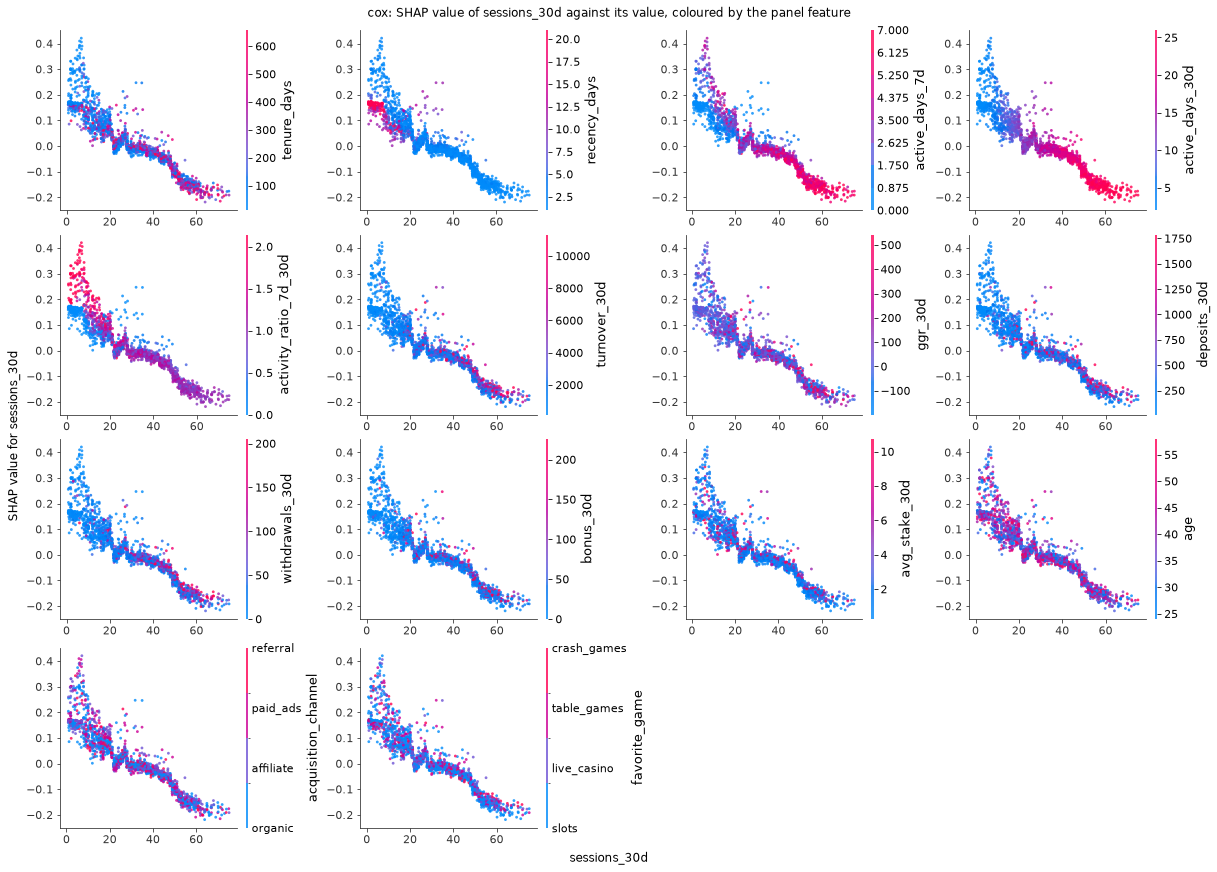

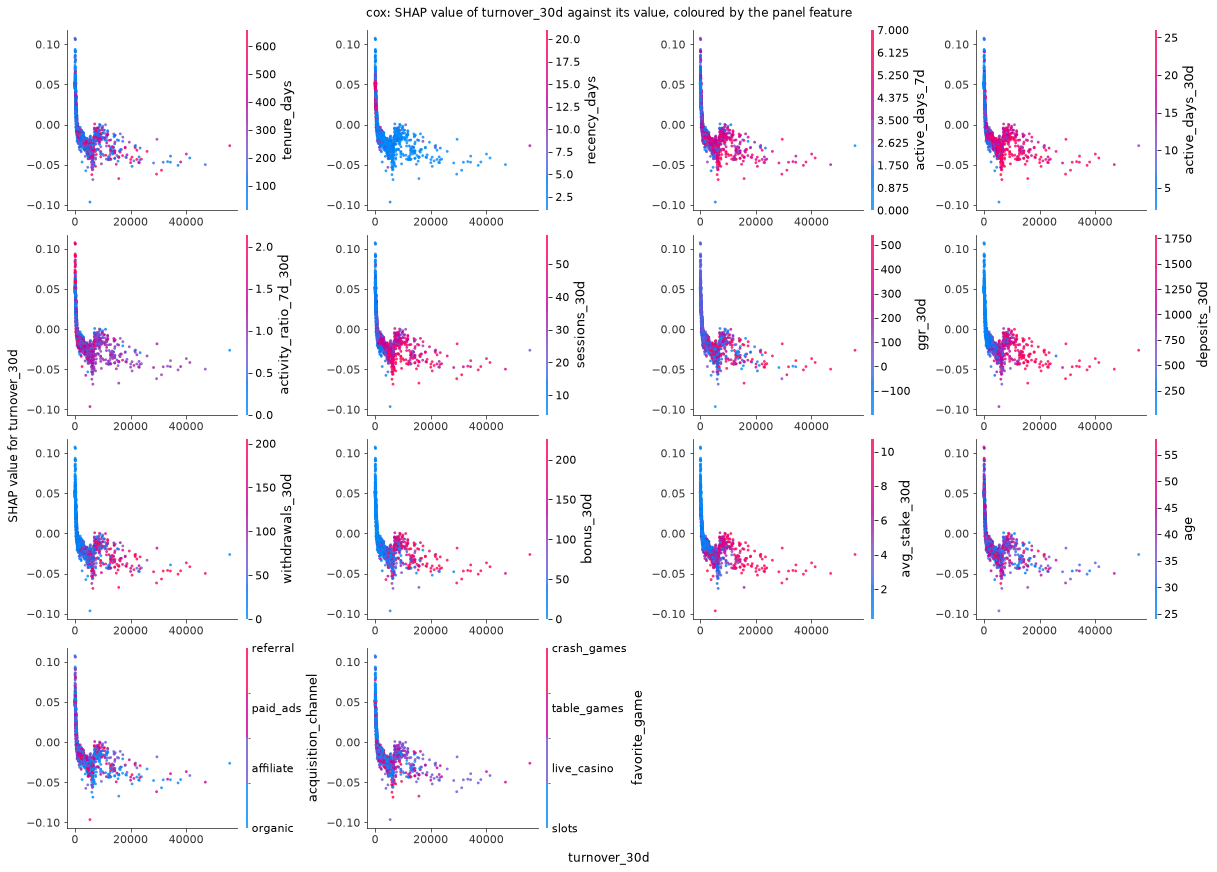

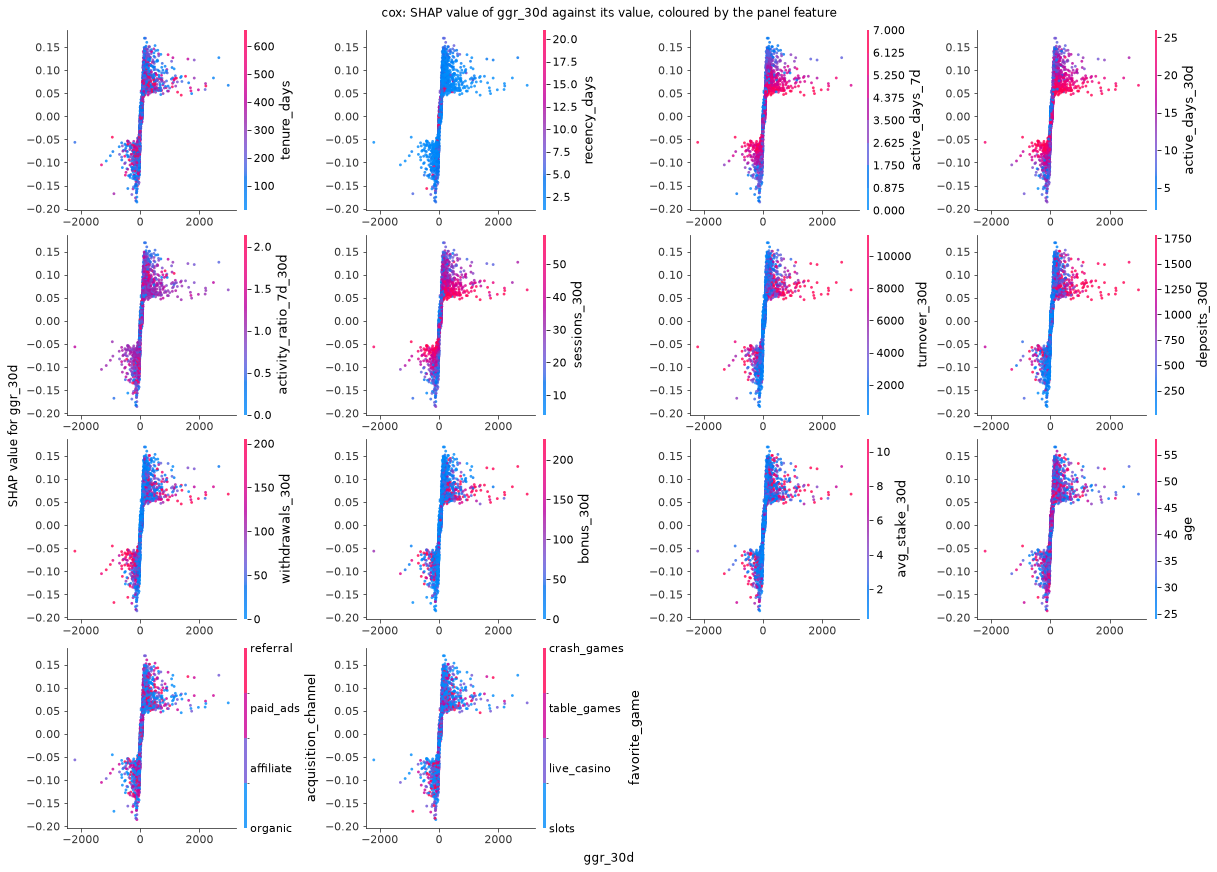

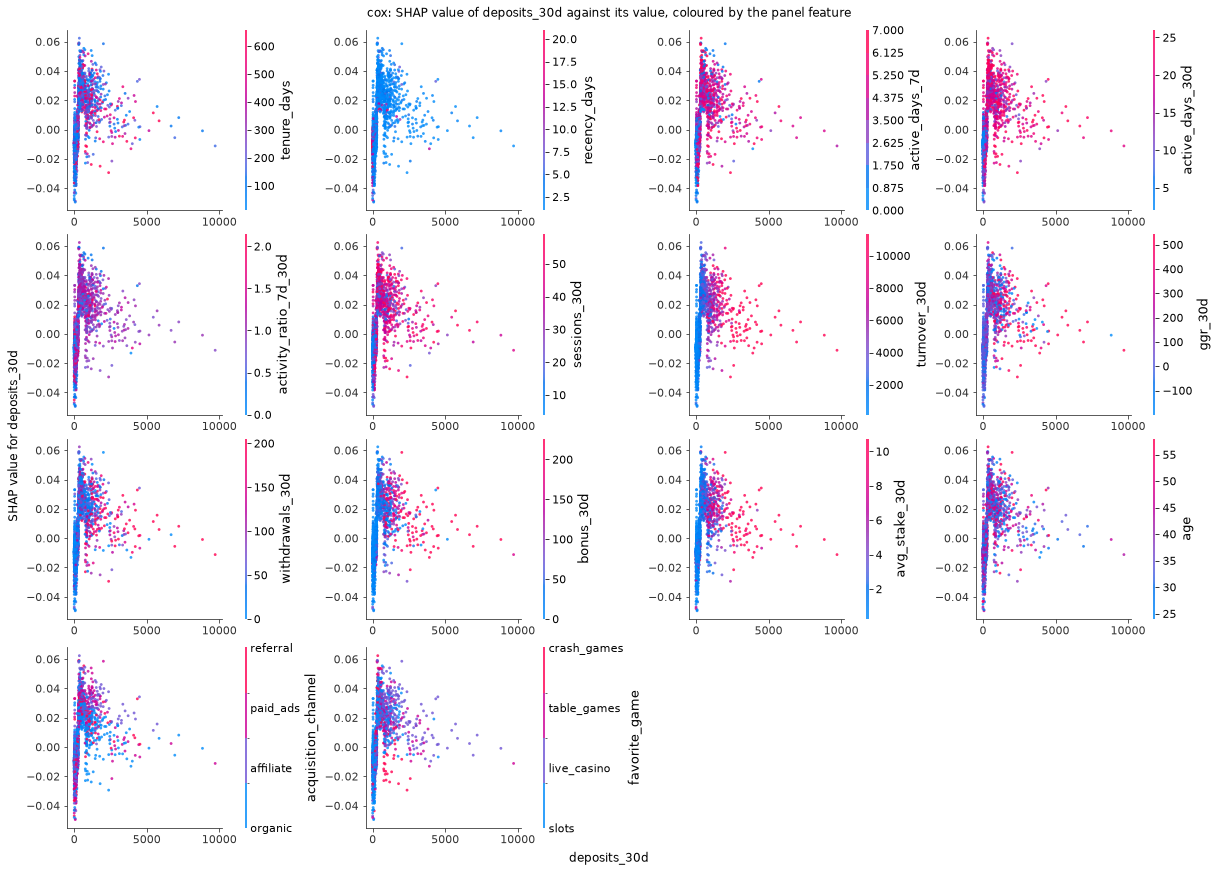

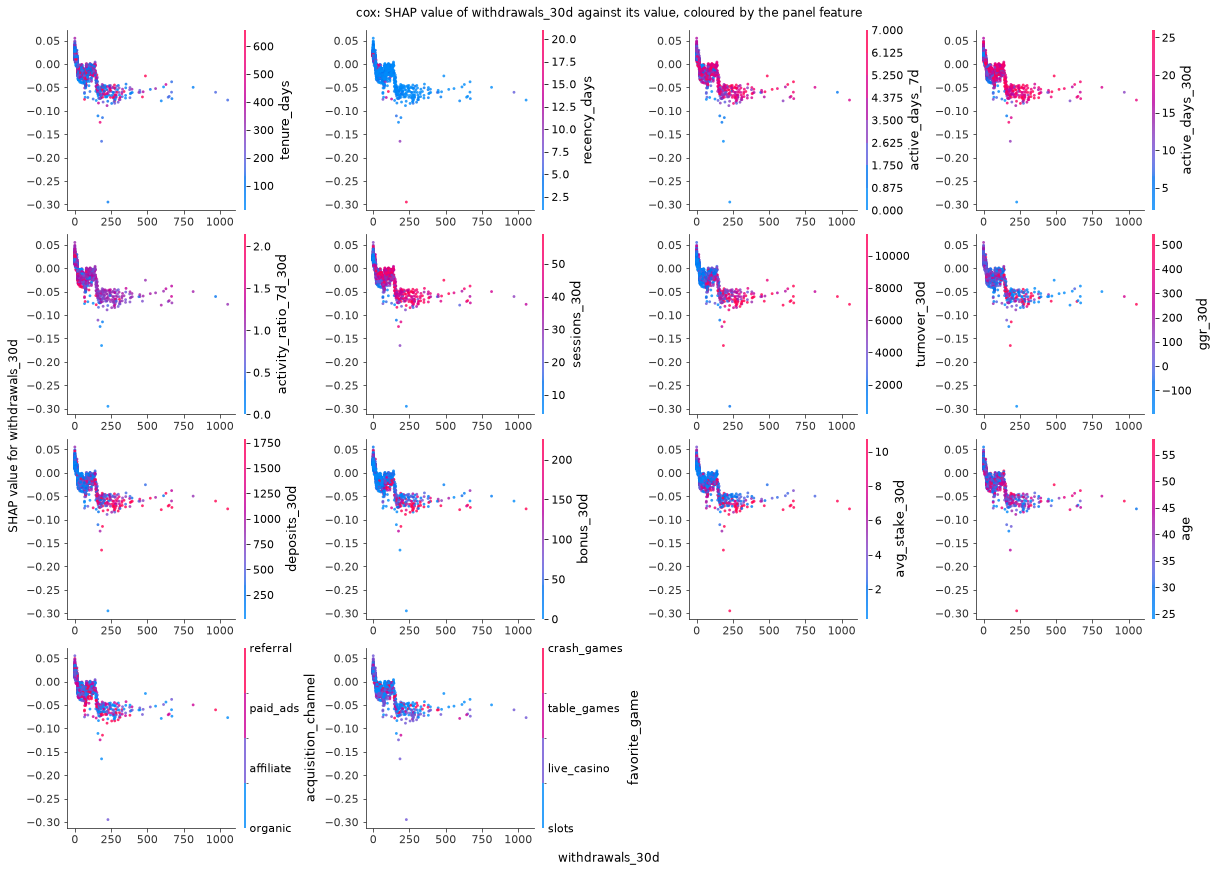

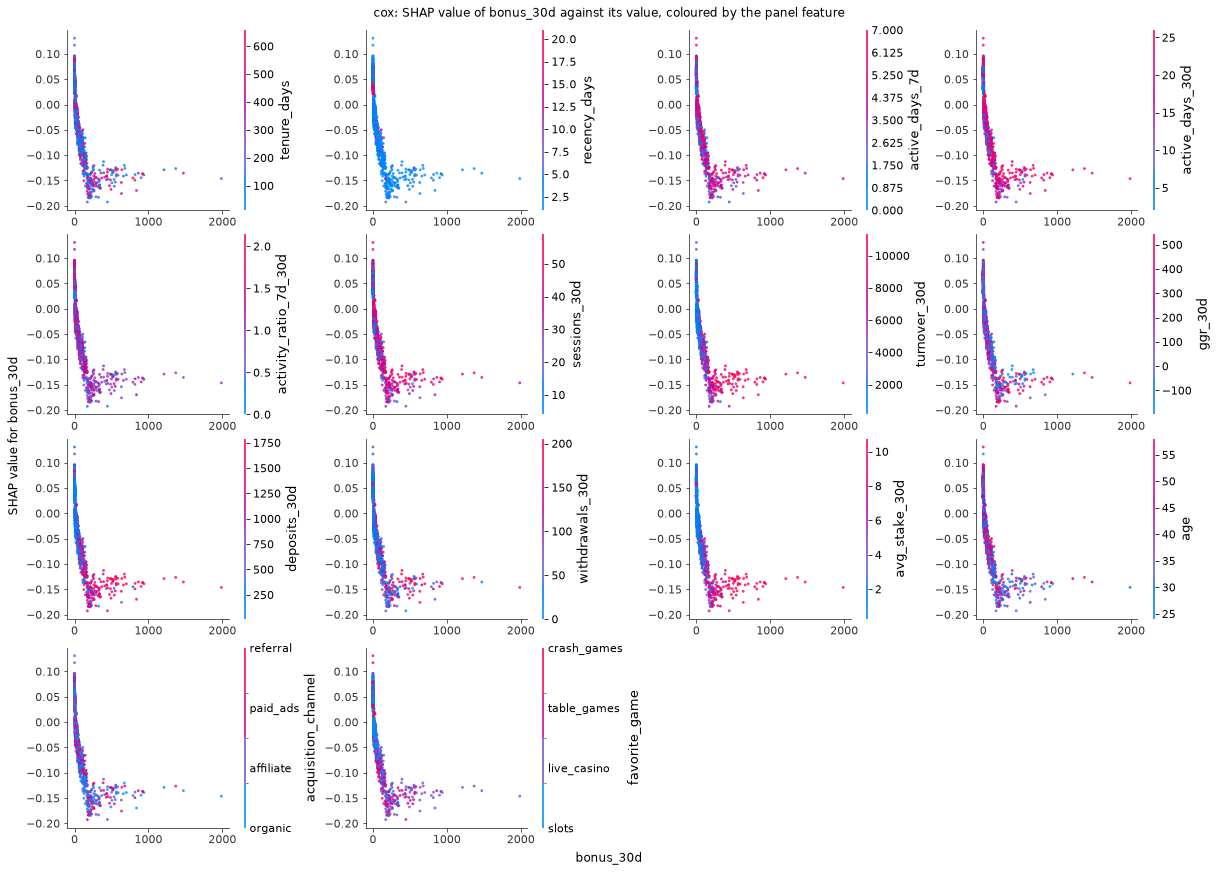

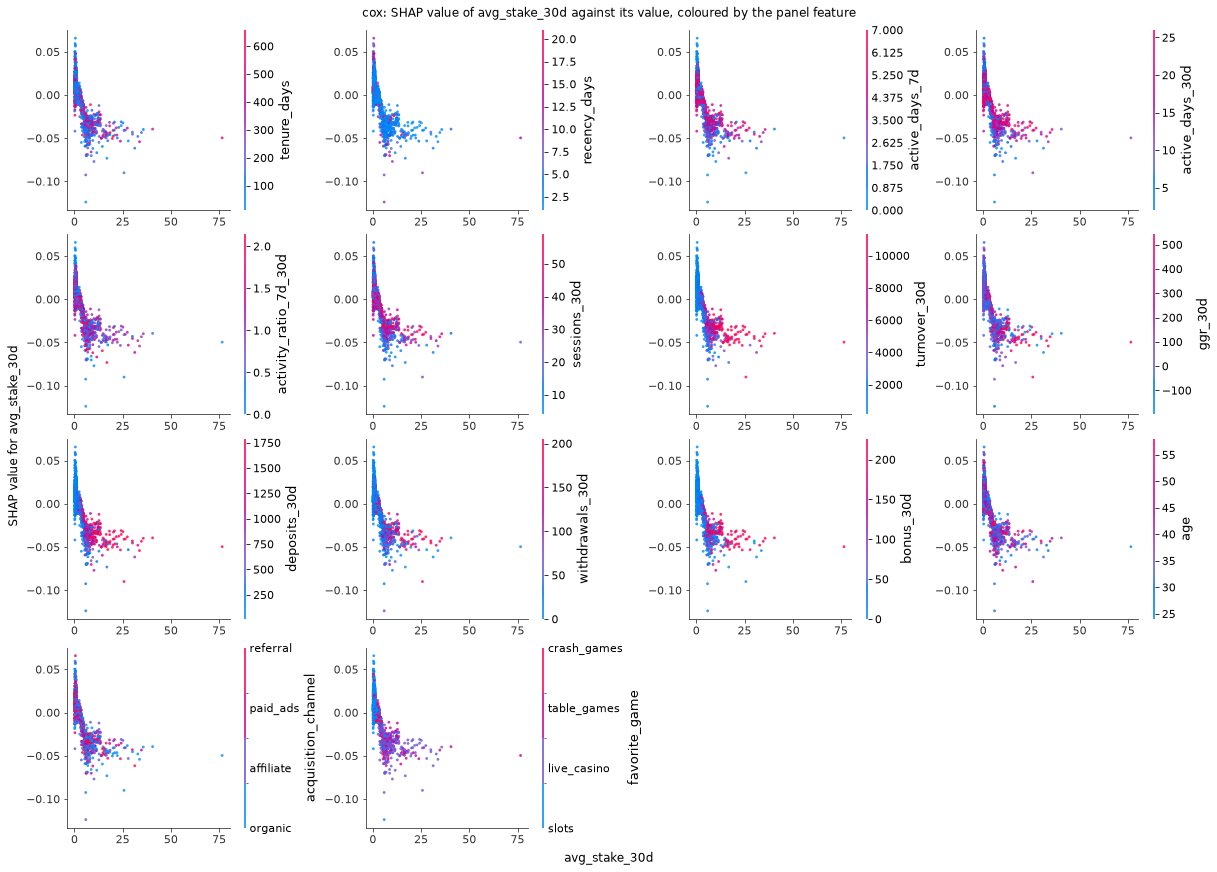

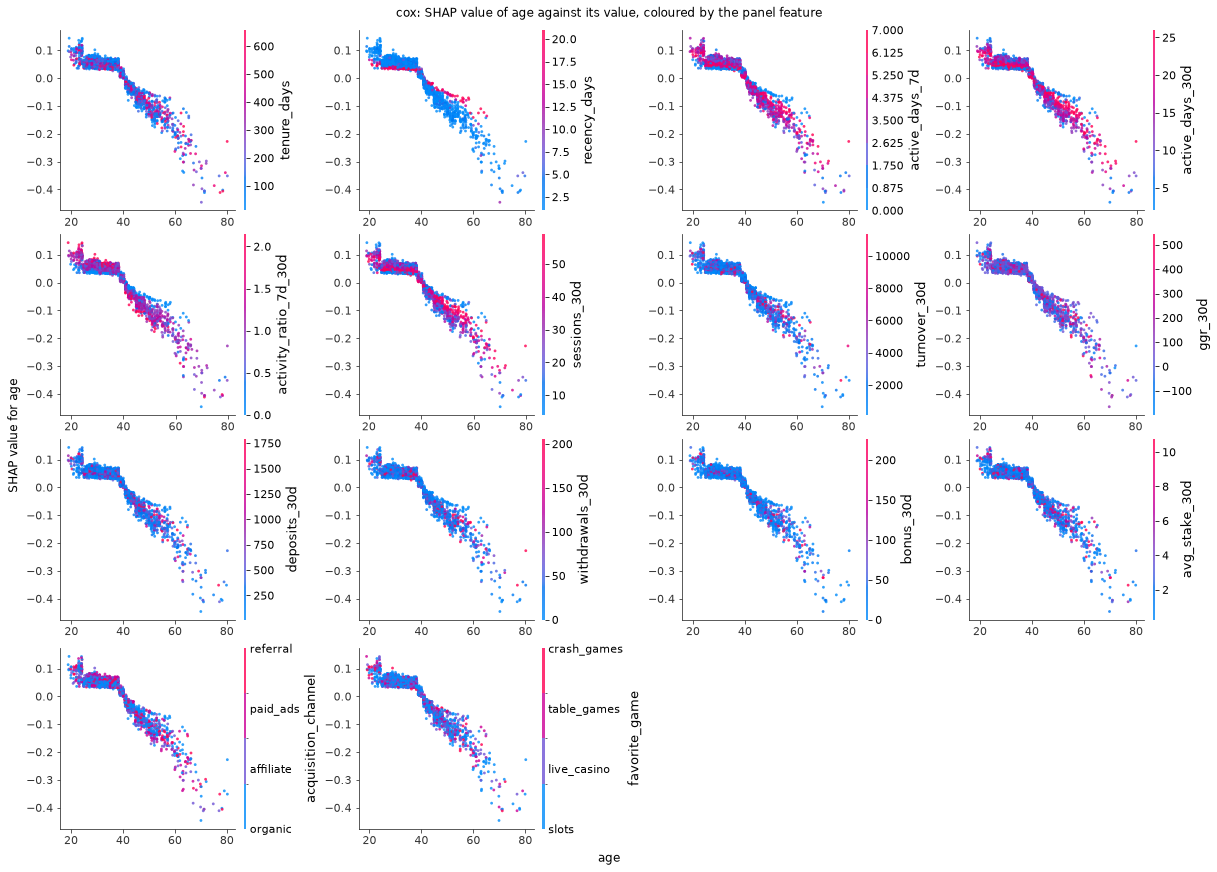

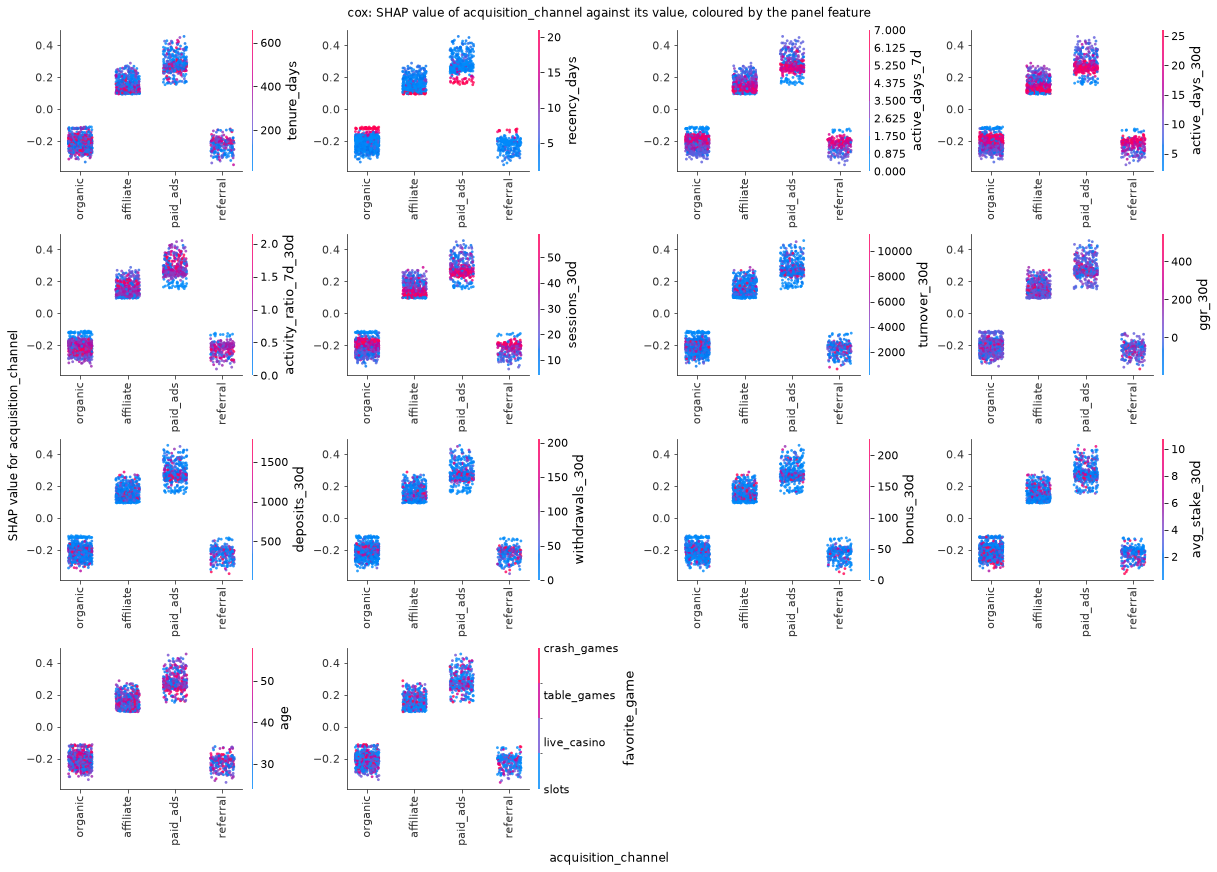

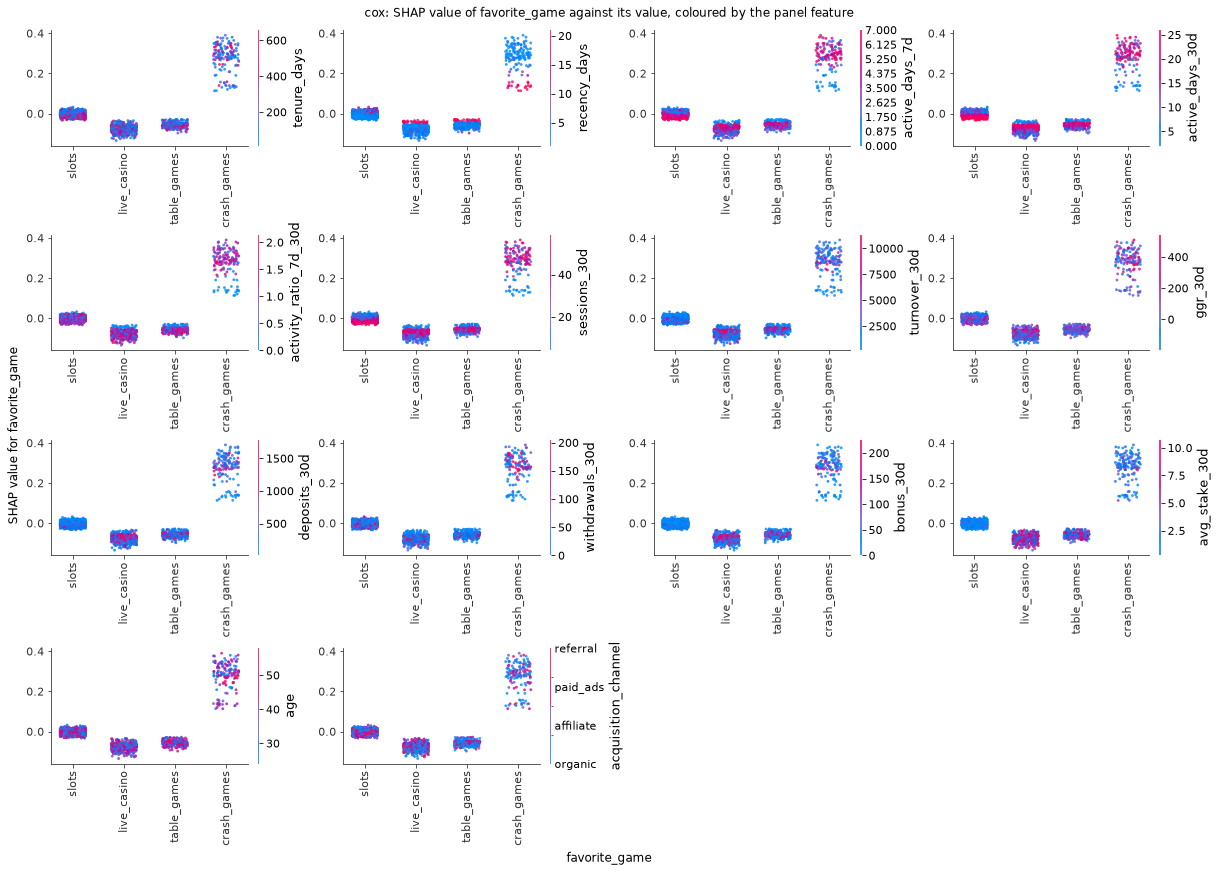

In [23]:
DEPENDENCE_MODELS = [best]  # add the other key of `models` to draw it as well
DEPENDENCE_COLUMNS = 4  # panels per row of a figure


def dependence_inputs(frame: pd.DataFrame) -> tuple[np.ndarray, pd.DataFrame, pd.DataFrame]:
    """SHAP matrix, numeric feature values and the values to display, as shap expects them."""
    shown = frame[FEATURES]
    codes = {name: shown[name].cat.codes for name in shown.select_dtypes("category")}
    values = frame[[f"shap_{name}" for name in FEATURES]].to_numpy()
    return values, shown.assign(**codes), shown


def dependence_grid(
    values: np.ndarray, numeric: pd.DataFrame, shown: pd.DataFrame, feature: str, title: str
) -> None:
    """Draw ``shap.dependence_plot`` of ``feature``, one panel per colouring feature."""
    others = [name for name in FEATURES if name != feature]
    n_rows = -(-len(others) // DEPENDENCE_COLUMNS)
    fig, axes = plt.subplots(
        n_rows,
        DEPENDENCE_COLUMNS,
        figsize=(4.2 * DEPENDENCE_COLUMNS, 3.0 * n_rows),
        dpi=72,  # keeps the 15 figures of dense scatter panels light in the notebook file
        layout="constrained",
        squeeze=False,
    )
    for ax, other in zip(axes.flat, others, strict=False):
        shap.dependence_plot(
            feature,
            values,
            numeric,
            display_features=shown,
            interaction_index=other,
            x_jitter=0.5,  # relative to the smallest gap between values: moves discrete ones only
            dot_size=8,
            alpha=0.8,
            ax=ax,
            show=False,
        )
        ax.set(xlabel="", ylabel="")  # one pair of axis labels per figure, set below
    for ax in axes.flat[len(others) :]:
        ax.set_visible(False)
    fig.supxlabel(feature)
    fig.supylabel(f"SHAP value for {feature}")
    fig.suptitle(title)
    plt.show()


# shap shuffles the drawing order and jitters with NumPy's global generator; seeding it
# keeps the figures identical between runs.
np.random.seed(SEED)
for name in DEPENDENCE_MODELS:
    inputs = dependence_inputs(explained[name][1])
    for feature in FEATURES:
        title = f"{name}: SHAP value of {feature} against its value, coloured by the panel feature"
        dependence_grid(*inputs, feature, title)

## 12. Remaining useful life: best model vs Kaplan-Meier

Remaining useful life (RUL) is the expected number of days until churn. The grid ends at
day 85, so it is the restricted mean `E[min(T, 85)] = 1 + S(1) + ... + S(84)`.

- **Model**: computed from each player's survival curve of the model and variant chosen
  in step 6.
- **Kaplan-Meier baseline**: the same number for everybody, from the Kaplan-Meier curve
  of the training data. This is what one can say without a model.
- **Observed**: within each decile of predicted RUL, the restricted mean of the
  Kaplan-Meier curve of the test players in that decile.

The summary compares both predictions with the realised `min(T, 85)` of every player.

In [24]:
tables["rul"], rul_summary = ev.rul_tables(
    t_test, e_test, test_surv[(best, best_variant)], TIMES, km_train
)
rul = tables["rul"]
fig = go.Figure(
    [
        go.Bar(
            x=rul["bin"],
            y=rul["predicted"],
            name=f"{best} {best_variant}",
            marker_color=COLORS[best],
        ),
        go.Bar(x=rul["bin"], y=rul["observed"], name="observed in the decile", marker_color=GREY),
    ]
)
baseline = line(rul["bin"], rul["km_baseline"], "Kaplan-Meier baseline", COLORS["high"], "dash")
fig.add_trace(baseline)
show(
    fig,
    "Test: remaining useful life by decile of predicted RUL",
    "decile of predicted RUL (1 = shortest)",
    f"expected days to churn, capped at {TIMES[-1]}",
)
display(pd.Series(rul_summary, name="value").to_frame(), rul)

,value
restricted_to_days,85.0000
mean_predicted,69.0607
mean_observed,69.3411
km_baseline,67.8575
mae_model,10.2587
mae_km,22.4506
rmse_model,15.9307
rmse_km,26.3444


,bin,n,predicted,observed,km_baseline
0,1,421,12.9042,13.5059,67.8575
1,2,420,47.3901,50.7238,67.8575
2,3,420,68.0878,69.8262,67.8575
3,4,420,74.5073,75.2119,67.8575
4,5,420,78.3404,77.9000,67.8575
5,6,420,80.4481,79.1381,67.8575
6,7,420,81.3778,80.2810,67.8575
7,8,420,81.6050,81.1119,67.8575
8,9,420,82.3310,82.6167,67.8575
9,10,420,83.7496,83.2286,67.8575


## 13. Backtest

Rolling origin over the monthly snapshots 2025-07-01 .. 2026-05-01. For every date both
models are refitted on all earlier snapshots, with labels as they were known on that
date, and then score the players at risk on that date. The forecast is compared with
what happened in the following 60 days.

Every date is forecast with `forecast`, the procedure of step 6: raw curves of the
refitted models, and curves calibrated by the generation three months older.

`role` says what the run above uses a date for. Hyperparameters were tuned on the `tune`
folds and the model was chosen on the `selection` folds, so only the `test` date and the
dates after it are untouched by every decision. `ibs_horizon` is the integrated Brier
score over days 1..60.

In [25]:
tables["backtest"] = backtest(generations, data_cutoff)
folds = tables["backtest"]

titles = [f"churn rate within {HORIZON} days", f"AUC at {HORIZON} days"]
fig = make_subplots(rows=1, cols=2, subplot_titles=titles)
actual = folds.drop_duplicates("snapshot_date")
fig.add_trace(
    line(actual["snapshot_date"], actual["observed_rate"], "observed", GREY, width=5), 1, 1
)
for (name, variant), part in folds.groupby(["model", "variant"], sort=False):
    style = (f"{name} {variant}", COLORS[name], DASHES[variant])
    fig.add_trace(line(part["snapshot_date"], part["predicted_rate"], *style), 1, 1)
    fig.add_trace(line(part["snapshot_date"], part["auc"], *style, showlegend=False), 1, 2)
fig.update_yaxes(tickformat=".0%", rangemode="tozero", row=1, col=1)
fig.update_xaxes(title_text="snapshot date")
show(fig, "Rolling-origin backtest", height=380)

errors = folds.assign(rate_error=folds["predicted_rate"] - folds["observed_rate"])
errors["abs_rate_error"] = errors["rate_error"].abs()
averaged = ["rate_error", "abs_rate_error", "auc", "brier", "ibs_horizon"]
display(errors.groupby(["model", "variant"], sort=False)[averaged].mean(), folds)

rate_error  abs_rate_error     auc   brier  ibs_horizon
model variant                                                            
cox   raw            -0.0060          0.0061  0.8648  0.1101       0.0475
      calibrated      0.0013          0.0053  0.8633  0.1105       0.0459
aft   raw             0.0135          0.0135  0.8627  0.1114       0.0471
      calibrated      0.0007          0.0053  0.8617  0.1111       0.0460

,snapshot_date,role,model,variant,train_rows,players,predicted_rate,observed_rate,auc,brier,ibs_horizon
0,2025-07-01,tune,cox,raw,39048,3899,0.2623,0.2729,0.8498,0.1153,0.0501
1,2025-07-01,tune,cox,calibrated,39048,3899,0.2683,0.2729,0.8462,0.1158,0.0483
2,2025-07-01,tune,aft,raw,39048,3899,0.2819,0.2729,0.8520,0.1160,0.0494
3,2025-07-01,tune,aft,calibrated,39048,3899,0.2662,0.2729,0.8517,0.1158,0.0483
4,2025-08-01,other,cox,raw,42947,3947,0.2680,0.2731,0.8611,0.1145,0.0493
5,2025-08-01,other,cox,calibrated,42947,3947,0.2677,0.2731,0.8604,0.1143,0.0478
6,2025-08-01,other,aft,raw,42947,3947,0.2905,0.2731,0.8586,0.1171,0.0496
7,2025-08-01,other,aft,calibrated,42947,3947,0.2664,0.2731,0.8584,0.1153,0.0481
8,2025-09-01,other,cox,raw,46894,3995,0.2633,0.2668,0.8572,0.1136,0.0496
9,2025-09-01,other,cox,calibrated,46894,3995,0.2733,0.2668,0.8553,0.1147,0.0484


## 14. Production model: refit on everything known on the scoring date

The selected family is refitted on every snapshot before the scoring date, with labels
as they are known on that date. The last three snapshots are only partly followed, which
censoring handles. The hyperparameters, including the number of boosting rounds, are the
tuned ones. This is the generation of the scoring date, the same object the backtest
builds for every earlier date.

Its calibrator comes from the generation three months older (`config.CALIBRATION_LAG`),
fitted on that generation's own snapshot, which has just been followed for the whole
grid. With the default calendar that is the test snapshot, so this calibrator is fitted
only here, after the test report. It is applied to the scores only if step 6 chose the
calibrated variant.

In [26]:
production = generations.model(best, config.SCORING_SNAPSHOT)
production_train = generations.history(config.SCORING_SNAPSHOT)
calibration_date = config.SCORING_SNAPSHOT - config.CALIBRATION_LAG
production_calibrator = generations.calibrator(best, calibration_date, config.SCORING_SNAPSHOT)
print(f"Calibrator: generation of {calibration_date.date()}")

sizes = {
    "evaluation (train)": describe(train),
    "production (all snapshots before scoring)": describe(production_train),
}
display(pd.DataFrame.from_dict(sizes, orient="index"))

# The production model is explained on the players it will score.
explained["production"] = explain(production, "production", scoring[MODEL_COLUMNS], SEED)
tables["feature_importance"] = pd.concat(
    [table for table, _ in explained.values()], ignore_index=True
)
tables["shap_values"] = pd.concat([shap for _, shap in explained.values()], ignore_index=True)
compared_models = tables["feature_importance"]["model"].isin([best, "production"])
importance_chart(
    tables["feature_importance"][compared_models],
    f"Feature importance: evaluation {best} (test sample) vs production (scoring sample)",
)

Calibrator: generation of 2026-04-01


,rows,players,snapshots,event_rate
evaluation (train),63229,13852,18,0.3481
production (all snapshots before scoring),88572,17695,24,0.3453


## 15. Evaluation vs production

The production model scores players whose outcomes are not known yet, so it cannot be
tested itself. What can be tested is its procedure: the same refit replayed on the test
date.

- `production` rows: the generation of the test date, fitted on every snapshot before it
  (three more months than the evaluation model), with the calibrator of the validation
  generation. They equal the `test` fold of the backtest.
- `evaluation` rows: the model frozen on the validation date, as reported in steps 4-9.

Neither has seen the outcomes of the test snapshot, so the difference is the effect of
the three extra months of training data.

In [27]:
replay = forecast(generations, config.TEST_SNAPSHOT, data_cutoff)
compared = {
    ("evaluation", "raw"): test_surv[(best, "raw")],
    ("evaluation", "calibrated"): test_surv[(best, "calibrated")],
    ("production", "raw"): replay.surv_by_model[f"{best}_raw"],
    ("production", "calibrated"): replay.surv_by_model[f"{best}_calibrated"],
}
tables["eval_vs_production"] = pd.DataFrame(
    [
        {
            "model": name,
            "variant": variant,
            **ev.summary_metrics(t_test, e_test, surv, TIMES, HORIZON),
            **ev.horizon_metrics(t_test, e_test, surv[:, K_HORIZON], HORIZON),
        }
        for (name, variant), surv in compared.items()
    ]
).drop(columns=["auc", "brier"])  # already reported as auc_horizon / brier_horizon
tables["eval_vs_production_curves"] = pd.concat(
    [
        ev.survival_curve_table(t_test, e_test, surv, TIMES).assign(model=name, variant=variant)
        for (name, variant), surv in compared.items()
    ],
    ignore_index=True,
)
tables["eval_vs_production_scores"] = pd.DataFrame(
    {
        "player_id": test["player_id"].to_numpy(),
        "churned": e_test & (t_test <= HORIZON),
        **{
            f"{name}_{variant}": 1 - surv[:, K_HORIZON]
            for (name, variant), surv in compared.items()
        },
    }
)
risk_correlation = spearmanr(
    models[best].predict_risk(X_test),
    generations.model(best, config.TEST_SNAPSHOT).predict_risk(X_test),
).statistic
churn_prob_gap = np.abs(
    compared[("evaluation", best_variant)][:, K_HORIZON]
    - compared[("production", best_variant)][:, K_HORIZON]
).mean()
agreement = {
    "spearman_risk_score": float(risk_correlation),
    "mean_abs_diff_churn_prob": float(churn_prob_gap),
}
display(tables["eval_vs_production"], pd.Series(agreement, name="agreement on test").to_frame())

,model,variant,c_index,ibs,brier_horizon,auc_horizon,predicted_rate,observed_rate
0,evaluation,raw,0.8239,0.0711,0.1091,0.8619,0.2575,0.258
1,evaluation,calibrated,0.8212,0.0705,0.1098,0.8604,0.2622,0.258
2,production,raw,0.8241,0.0712,0.1093,0.8619,0.2579,0.258
3,production,calibrated,0.8217,0.0708,0.1105,0.8606,0.2630,0.258


,agreement on test
spearman_risk_score,0.9972
mean_abs_diff_churn_prob,0.0074


In [28]:
titles = [
    "mean predicted survival vs Kaplan-Meier",
    f"P(churn within {HORIZON} days), {best_variant}, one point per player",
]
fig = make_subplots(rows=1, cols=2, subplot_titles=titles)
curves = tables["eval_vs_production_curves"]
observed = curves.drop_duplicates("day")
fig.add_trace(
    line(observed["day"], observed["observed"], "observed (Kaplan-Meier)", GREY, width=5), 1, 1
)
role_colors = {"evaluation": COLORS[best], "production": COLORS["production"]}
for (name, variant), part in curves.groupby(["model", "variant"], sort=False):
    label = f"{name} {variant}"
    fig.add_trace(
        line(part["day"], part["predicted"], label, role_colors[name], DASHES[variant]), 1, 1
    )
probabilities = tables["eval_vs_production_scores"]
players_on_test = go.Scatter(
    x=probabilities[f"evaluation_{best_variant}"],
    y=probabilities[f"production_{best_variant}"],
    mode="markers",
    marker={"size": 4, "opacity": 0.4, "color": COLORS["production"]},
    showlegend=False,
    hoverinfo="skip",
)
fig.add_trace(players_on_test, 1, 2)
fig.add_trace(line([0, 1], [0, 1], "y = x", GREY, "dash", showlegend=False), 1, 2)
fig.update_xaxes(title_text="days since snapshot", row=1, col=1)
fig.update_yaxes(tickformat=".0%", row=1, col=1)
fig.update_xaxes(title_text="evaluation model", row=1, col=2)
fig.update_yaxes(title_text="production model", row=1, col=2)
show(fig, "Evaluation model vs the production procedure on the test snapshot")

## 16. Riskiest players

The production model scores every player at risk on the scoring snapshot (the day after
the data end). Players are ranked by the probability of churning within 60 days,
calibrated or raw as chosen in step 6; calibration creates ties, which the raw
probability breaks. Risk segments are fixed thresholds on that probability
(`config.RISK_SEGMENTS`).

Expect the very top of the list to be players who are days away from the 30-day
inactivity threshold: their churn is close to a matter of definition. Step 17 therefore
also looks at the riskiest players among those who were active in the last week.

In [29]:
scoring_calibrator = production_calibrator if best_variant == "calibrated" else None
scores, score_curves = score_players(production, scoring_calibrator, scoring)
score_curves.insert(0, "player_id", scores["player_id"])
tables["scores"] = scores
tables["score_curves"] = score_curves
tables["top_risk_users"] = scores.head(config.TOP_N_RISKY)

segments = [name for name, _ in config.RISK_SEGMENTS]
segment_sizes = scores["risk_segment"].value_counts().reindex(segments, fill_value=0)
titles = ["players per risk segment", f"P(churn within {HORIZON} days)"]
fig = make_subplots(rows=1, cols=2, subplot_titles=titles)
segment_bars = go.Bar(
    x=segments,
    y=segment_sizes,
    text=segment_sizes,
    marker_color=[COLORS[name] for name in segments],
)
fig.add_trace(segment_bars, 1, 1)
histogram = go.Histogram(
    x=scores[f"churn_prob_{HORIZON}d"],
    xbins={"start": 0, "end": 1.0001, "size": 0.025},
    marker_color=COLORS["production"],
)
fig.add_trace(histogram, 1, 2)
fig.update_xaxes(tickformat=".0%", row=1, col=2)
title = f"Scoring snapshot {config.SCORING_SNAPSHOT.date()}: {len(scores):,} players at risk"
show(fig, title, height=340, showlegend=False)

print(f"Segment thresholds on P(churn within {HORIZON} days): {dict(config.RISK_SEGMENTS)}")
shown = ["risk_rank", "player_id", f"churn_prob_{HORIZON}d", "rul_days", "risk_segment"]
shown += ["recency_days", "active_days_30d", "tenure_days"]
display(scores[shown].head(20))

Segment thresholds on P(churn within 60 days): {'high': 0.7, 'medium': 0.4, 'low': 0.0}


,risk_rank,player_id,churn_prob_60d,rul_days,risk_segment,recency_days,active_days_30d,tenure_days
0,1,438,1.0,1.0,high,30,1,67
1,2,853,1.0,1.0,high,30,1,34
2,3,3494,1.0,1.0,high,30,1,234
3,4,4369,1.0,1.0,high,30,1,67
4,5,4423,1.0,1.0,high,30,1,216
5,6,5814,1.0,1.0,high,30,1,30
6,7,6034,1.0,1.0,high,30,1,48
7,8,6201,1.0,1.0,high,30,1,57
8,9,7305,1.0,1.0,high,30,1,82
9,10,7764,1.0,1.0,high,30,1,78


## 17. Scoring of the riskiest players

The scorecard of a player holds:

- the probability of churning within 7, 14, 30 and 60 days;
- the remaining useful life in days (capped at 85);
- the risk segment;
- the three features that push the player's risk up the most, with their SHAP values on
  the risk-score scale;
- the individual survival curve.

A player last active `r` days before the snapshot cannot churn before day `31 - r`. The
model starts its clock on that day, so an individual curve stays at 100% until then and
the short-horizon probabilities of recently active players are exactly zero.

In [30]:
probability_columns = [f"churn_prob_{h}d" for h in config.SCORE_HORIZONS]
drivers = ["driver_1", "driver_2", "driver_3"]
scorecard = ["risk_rank", "player_id", "risk_segment", *probability_columns, "rul_days"]
scorecard += ["recency_days", *drivers]

print(f"Top {config.TOP_N_RISKY} players are saved as `top_risk_users`; the first 15:")
display(tables["top_risk_users"][scorecard].head(15))

recently_active = scores[scores["recency_days"] <= 7]
print("Riskiest players among those active in the last 7 days:")
display(recently_active[scorecard].head(15))

Top 100 players are saved as `top_risk_users`; the first 15:


,risk_rank,player_id,risk_segment,churn_prob_7d,churn_prob_14d,churn_prob_30d,churn_prob_60d,rul_days,recency_days,driver_1,driver_2,driver_3
0,1,438,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
1,2,853,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
2,3,3494,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
3,4,4369,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
4,5,4423,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
5,6,5814,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
6,7,6034,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
7,8,6201,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
8,9,7305,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d
9,10,7764,high,1.0,1.0,1.0,1.0,1.0,30,recency_days,active_days_7d,activity_ratio_7d_30d


Riskiest players among those active in the last 7 days:


,risk_rank,player_id,risk_segment,churn_prob_7d,churn_prob_14d,churn_prob_30d,churn_prob_60d,rul_days,recency_days,driver_1,driver_2,driver_3
438,439,19264,high,0.0,0.0,0.4954,0.7778,42.1884,4,active_days_7d,activity_ratio_7d_30d,acquisition_channel
448,449,1088,high,0.0,0.0,0.5106,0.7727,44.7185,5,active_days_30d,active_days_7d,acquisition_channel
458,459,14102,high,0.0,0.0,0.5152,0.7500,44.7865,6,tenure_days,active_days_7d,acquisition_channel
461,462,16411,high,0.0,0.0,0.5152,0.7143,45.1580,6,active_days_30d,recency_days,active_days_7d
468,469,17306,high,0.0,0.0,0.5152,0.7143,45.2508,6,tenure_days,active_days_30d,active_days_7d
470,471,1998,high,0.0,0.0,0.5106,0.7143,45.8065,5,active_days_30d,acquisition_channel,tenure_days
475,476,6419,medium,0.0,0.0,0.5106,0.6667,47.3090,5,tenure_days,active_days_7d,active_days_30d
476,477,1250,medium,0.0,0.0,0.5106,0.6667,47.3107,5,tenure_days,active_days_30d,acquisition_channel
483,484,19533,medium,0.0,0.0,0.5333,0.6462,46.8838,7,tenure_days,recency_days,active_days_7d
484,485,7022,medium,0.0,0.0,0.5333,0.6462,47.0285,7,active_days_30d,recency_days,active_days_7d


In [31]:
survival = score_curves.set_index("player_id")
days = [0, *TIMES]
average = line(days, [1.0, *survival.mean()], "average of all scored players", GREY, "dash", 4)
fig = go.Figure(average)
# Neighbours in the ranking have almost the same curve, so show one player per segment.
examples = recently_active.groupby("risk_segment", sort=False).head(1)
for player_id, segment in zip(examples["player_id"], examples["risk_segment"], strict=True):
    label = f"player {player_id} ({segment} risk)"
    fig.add_trace(line(days, [1.0, *survival.loc[player_id]], label, COLORS[segment]))
fig.add_vline(x=HORIZON, line_dash="dot", line_color=GREY)
show(
    fig,
    "Survival curves: the riskiest recently active player of each segment",
    "days since the scoring snapshot",
    "probability of not having churned",
    yaxis_tickformat=".0%",
    yaxis_range=[0, 1.02],
)

player = recently_active.iloc[0]
print(f"Risk drivers of player {player['player_id']} (rank {player['risk_rank']}):")
display(
    pd.DataFrame(
        {
            "feature": [player[name] for name in drivers],
            "value": [player[player[name]] for name in drivers],
            "shap": [player[f"{name}_shap"] for name in drivers],
        }
    )
)

Risk drivers of player 19264 (rank 439):


,feature,value,shap
0,active_days_7d,1,0.5026
1,activity_ratio_7d_30d,0.2143,0.4713
2,acquisition_channel,paid_ads,0.2681


## 18. Artifacts for the dashboard

Everything the dashboard reads is written to `artifacts/`:

- one parquet table per chart (the `tables` collected above);
- `metrics.json` with the configuration, dataset sizes, tuning results and headline
  numbers;
- the two evaluation models, the production model and the calibrators as JSON under
  `artifacts/models/`.

In [32]:
models_dir = ARTIFACTS_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)
for name, table in tables.items():
    table.to_parquet(ARTIFACTS_DIR / f"{name}.parquet", index=False)
for name, model in (models | {"production": production}).items():
    model.save(models_dir / name)
for name, calibrator in (calibrators | {"production": production_calibrator}).items():
    (models_dir / f"calibrator_{name}.json").write_text(json.dumps(calibrator.to_dict()))

train_span = (config.TRAIN_SNAPSHOTS[0], config.TRAIN_SNAPSHOTS[-1])
production_snapshots = production_train["snapshot_date"]
production_span = (production_snapshots.min(), production_snapshots.max())
metadata = {
    "generated_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "horizon_days": HORIZON,
    "inactivity_days": config.INACTIVITY_DAYS,
    "max_follow_up_days": config.MAX_FOLLOW_UP_DAYS,
    "calibration_lag_months": config.CALIBRATION_LAG.months,
    "time_grid": [int(TIMES[0]), int(TIMES[-1])],
    "features": FEATURES,
    "snapshots": {
        "train": [str(day.date()) for day in train_span],
        "val": str(config.VAL_SNAPSHOT.date()),
        "test": str(config.TEST_SNAPSHOT.date()),
        "scoring": str(config.SCORING_SNAPSHOT.date()),
        "tune": [str(day.date()) for day in config.TUNE_SNAPSHOTS],
        "selection": [str(day.date()) for day in config.SELECTION_SNAPSHOTS],
        "production_train": [str(day.date()) for day in production_span],
        "production_calibration": str(calibration_date.date()),
    },
    "datasets": {
        "train": describe(train),
        "val": describe(val, full_follow_up=True),
        "test": describe(test, full_follow_up=True),
        "production_train": describe(production_train),
        "scoring": {"rows": len(scoring)},
    },
    "tuning": {
        "n_trials": N_TRIALS,
        "tune_ibs": tune_ibs,
        "val_ibs": val_ibs,
        "best_params": tuned,
    },
    "selection": selection,
    "best_model": best,
    "best_variant": best_variant,
    "n_bootstrap": N_BOOTSTRAP,
    "rul": rul_summary,
    "eval_vs_production_agreement": agreement,
    "risk_segments": dict(config.RISK_SEGMENTS),
    "seed": SEED,
}
(ARTIFACTS_DIR / "metrics.json").write_text(json.dumps(metadata, indent=2))

written = sorted(path for path in ARTIFACTS_DIR.rglob("*") if path.is_file())
listing = {
    "file": [str(path.relative_to(ARTIFACTS_DIR)) for path in written],
    "kB": [round(path.stat().st_size / 1024, 1) for path in written],
}
display(pd.DataFrame(listing))

,file,kB
0,backtest.parquet,8.5
1,bootstrap_differences.parquet,4.2
2,bootstrap_draws.parquet,41.3
3,bootstrap_summary.parquet,4.5
4,calibration.parquet,5.7
5,eval_vs_production.parquet,5.2
6,eval_vs_production_curves.parquet,8.0
7,eval_vs_production_scores.parquet,112.1
8,feature_importance.parquet,3.8
9,hazard.parquet,25.8


## 19. Dashboard

The Streamlit dashboard reads only `artifacts/` and shows every section of this notebook
interactively, in English (default) and Russian:

```bash
uv run streamlit run dashboard/app.py
```